# ✈️ TravelWithAgents — a multi-agent travel planner

**IS469 GenAI · class project**

A trip request goes in. A day-by-day itinerary you could actually follow comes out. Every step is done by a
role-specialised agent or a plain-code component, and the result is compared against a **single-prompt
baseline**.

| Step | Component | Type | What it produces |
|:--|:--|:--|:--|
| A | **Ingestion** | code + Google Places API (one-off per city) | `data/places/places_<city>.csv` |
| 0 | **Parser agent** | LLM | structured `TripRequest` |
| 1 | **Scout agent** | LLM + tools | candidate pool of ~25–35 places |
| 2 | **Persona agents** (Adventurer, Foodie, Culture buff, Budget-keeper) | 4 × LLM | each persona's own draft timetable + ratings |
| 3 | **Selector** | code | final places, chosen by **persona weights that sum to 1** |
| 4 | **Route optimiser** | code + Google Routes API | places grouped into days by area, shortest order per day, timed schedule |
| 5 | **Feasibility agent** | LLM + tools, in a validator loop (max 3 rounds) | a plan with no hard violations |
| 6 | **Baseline** | one LLM prompt | the same task done in a single call |
| 7 | **Evaluator agent** | code checks + LLM judge + LLM agent with tools | scores for both plans |

**Course topics demonstrated**

1. **Agentic AI (Topic 7):** tool calling through a harness, step budgets, role-specialised agents, a
   validator → repair loop, and code vs agent routing decisions.
2. **Inference & evaluation (Topics 5–6):** verifiable checks before an LLM judge, a pairwise judge run in both
   orders (position-bias mitigation), a judge from a different model family (self-preference), validating the
   judge against human labels, and a **temperature** experiment on the persona agents.

**About the harness.** An LLM never runs anything itself. When it wants a tool, it returns a structured request
(`{"name": "is_open", "arguments": {...}}`). The harness in Step "LLM harness" below runs the real Python
function, sends the result back, enforces the step budget and logs every call.

**Who owns what (duo split).** Cells are tagged **[A]** (data & routing) or **[B]** (agents & evaluation).
**[A+B]** cells are shared contracts: change them together.

## Setup — install packages
Runs on a plain **CPU** Colab runtime. All LLMs are called over the API, so no GPU is needed.

In [1]:
%pip install -q "openai>=1.40" pandas requests scikit-learn

DEPRECATION: Loading egg at /opt/anaconda3/lib/python3.12/site-packages/crepe-0.0.16-py3.12.egg is deprecated. pip 24.3 will enforce this behaviour change. A possible replacement is to use pip for package installation. Discussion can be found at https://github.com/pypa/pip/issues/12330
Note: you may need to restart the kernel to use updated packages.


## Setup — configuration and API keys **[A+B]**

Keys are read from a **`.env` file next to this notebook** (copy `.env.example`, one `NAME=value` per line),
then **Colab Secrets** (🔑 icon in the left sidebar). You are only prompted if a required key is in neither.
**Never paste a key into a cell**, and never commit `.env` (it is in `.gitignore`).

| Secret name | Needed for | Required? |
|:--|:--|:--|
| `GROQ_API_KEY` | all agents (default provider) | **yes** |
| `GEMINI_API_KEY` | judge + evaluator from a *different* model family | recommended |
| `GOOGLE_MAPS_API_KEY` | ingestion (Places API) and real travel times (Routes API) | only for the person who ingests / routes |

Without `GOOGLE_MAPS_API_KEY` the notebook still runs: it uses cached city files, falls back to a small built-in
**Hanoi sample** for development, and estimates travel times from straight-line distance (clearly marked as
`estimate` in the outputs).

In [33]:
import os, sys, json, time, re, math, hashlib, random, itertools, copy, difflib
from collections import deque, defaultdict, Counter
from datetime import date, timedelta
import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules

# ---- where files live -------------------------------------------------------------
# In Colab, set USE_DRIVE = True to keep cached data between sessions (mounts Google Drive).
USE_DRIVE = False
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/TravelWithAgents"
else:
    BASE_DIR = "."
PLACES_DIR  = os.path.join(BASE_DIR, "data", "places")
CACHE_DIR   = os.path.join(BASE_DIR, "data", "cache")
RESULTS_DIR = os.path.join(BASE_DIR, "eval", "results")
for d in (PLACES_DIR, CACHE_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

# ---- secrets ------------------------------------------------------------------------
# Keys live in a file named .env next to this notebook (copy .env.example). One per line: NAME=value
def _find_dotenv():
    here = os.path.abspath(os.getcwd())
    for d in dict.fromkeys([os.path.abspath(BASE_DIR), here, os.path.dirname(here)]):
        if os.path.exists(os.path.join(d, ".env")):
            return os.path.join(d, ".env")
    return None

def load_dotenv_file():
    """Read NAME=value lines from .env into os.environ (.env wins over values set earlier in the kernel)."""
    path = _find_dotenv()
    if not path:
        print("No .env file found next to the notebook (or one folder up).")
        return
    loaded = []
    for n, line in enumerate(open(path, encoding="utf-8-sig"), 1):
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        if line.startswith("export "):
            line = line[7:].strip()
        if "=" not in line:
            print(f"  ⚠️ .env line {n} ignored: no NAME= in front of it (expected e.g. GROQ_API_KEY=gsk_...)")
            continue
        k, v = line.split("=", 1)
        k, v = k.strip(), v.strip().strip('"').strip("'")
        if k and v:
            os.environ[k] = v
            loaded.append(k)
    print(f"Loaded from {path}: {', '.join(loaded) or 'no keys'}")

load_dotenv_file()

def get_secret(name, required=False):
    """os.environ (incl. .env) -> Colab secret -> (if required) a secure prompt as a last resort."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v:
            os.environ[name] = v
            return v
    except Exception:
        pass
    if required:
        import getpass
        print(f"{name} was not found in .env or Colab Secrets.")
        v = getpass.getpass(f"Enter {name}: ")
        os.environ[name] = v
        return v
    return None

GROQ_API_KEY        = get_secret("GROQ_API_KEY", required=True)
GEMINI_API_KEY      = get_secret("GEMINI_API_KEY")
GOOGLE_MAPS_API_KEY = get_secret("GOOGLE_MAPS_API_KEY")
if not GROQ_API_KEY.startswith("gsk_"):
    print("  ⚠️ GROQ_API_KEY doesn't start with 'gsk_' - check you pasted the Groq key, not another one.")

# ---- models -------------------------------------------------------------------------
# Every provider below speaks the OpenAI chat format, so switching is base_url + model name.
PROVIDERS = {
    "groq":   {"base_url": "https://api.groq.com/openai/v1", "key": GROQ_API_KEY,   "tpm": 8000},
    "gemini": {"base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
               "key": GEMINI_API_KEY, "tpm": 200000},
}
MODELS = {
    "strong": {"provider": "groq", "model": "openai/gpt-oss-120b"},
    "small":  {"provider": "groq", "model": "openai/gpt-oss-20b"},
    # The judge should NOT be the model family that wrote the plans (self-preference bias, Topic 6).
    "judge":  ({"provider": "gemini", "model": "gemini-3.5-flash"} if GEMINI_API_KEY
               else {"provider": "groq", "model": "openai/gpt-oss-20b"}),
}
# Which model each agent uses. The baseline and the feasibility agent share the strong model, so the
# multi-agent system never gets a bigger model than the baseline.
AGENT_ROLE = {"parser": "small", "scout": "small", "persona": "small",
              "feasibility": "strong", "baseline": "strong", "judge": "judge", "evaluator": "judge"}

# ---- Google Maps usage guards (keeps you inside the free monthly allowance) ---------
USE_GOOGLE_ROUTES      = True   # real travel times when a Maps key is present
ROUTES_ELEMENT_BUDGET  = 2500   # hard cap on Route Matrix elements per notebook session
TRAVEL_MODE            = "DRIVE"  # taxi / Grab; short hops are treated as walks (see routing cell)

print("Colab:", IN_COLAB, "| data dir:", os.path.abspath(BASE_DIR))
print("Judge model:", MODELS["judge"], "| Google Maps key:", "yes" if GOOGLE_MAPS_API_KEY else "no (offline mode)")

Loaded from /Users/geraldchee/Documents/GitHub/TravelWithAgents/.env: GROQ_API_KEY, GEMINI_API_KEY, GOOGLE_MAPS_API_KEY
Colab: False | data dir: /Users/geraldchee/Documents/GitHub/TravelWithAgents
Judge model: {'provider': 'gemini', 'model': 'gemini-3.5-flash'} | Google Maps key: yes


## LLM harness **[B]**

Everything an agent does goes through these functions:

- `chat()` calls the model, paces requests to stay under the free-tier **tokens-per-minute** limit, retries on
  rate limits (429) and server errors, and logs agent, model, tokens and seconds for every call
  (`CALL_LOG`, used for the cost table at the end).
- `chat_json()` asks for JSON, parses it robustly and, if the output is invalid, sends the error back for one or
  two repair attempts.
- `run_tool_agent()` is the **agent loop** from the Topic 7 lab: the model plans a step, the harness executes the
  tool call it asked for, feeds the observation back, and stops at a **step budget**. On the last step it removes
  the tools and forces a final answer.

In [34]:
from openai import OpenAI
import openai as _openai

_CLIENTS = {}
def get_client(provider):
    if provider not in _CLIENTS:
        cfg = PROVIDERS[provider]
        if not cfg["key"]:
            raise RuntimeError(f"No API key for provider '{provider}'.")
        # Ask for gzip, not Brotli: older `brotli` packages (common in conda envs) crash the HTTP decoder
        # with "process() takes no keyword arguments".
        _CLIENTS[provider] = OpenAI(base_url=cfg["base_url"], api_key=cfg["key"], max_retries=0, timeout=120,
                                    default_headers={"Accept-Encoding": "gzip, deflate"})
    return _CLIENTS[provider]

CALL_LOG = []                       # one row per LLM call
_TOKEN_WINDOW = defaultdict(deque)  # model -> deque[(timestamp, tokens)] for client-side TPM pacing

def _pace(model, provider, est_tokens):
    """Wait until sending ~est_tokens keeps this model under its tokens-per-minute limit."""
    limit = PROVIDERS[provider]["tpm"]
    win = _TOKEN_WINDOW[model]
    while True:
        now = time.time()
        while win and now - win[0][0] > 60:
            win.popleft()
        used = sum(t for _, t in win)
        if used + est_tokens <= limit or not win:
            return
        wait = 60 - (now - win[0][0]) + 0.5
        print(f"    ⏳ pacing {model}: waiting {wait:.0f}s for the per-minute token limit")
        time.sleep(max(wait, 1))

class PromptTooLarge(Exception):
    """A single request is bigger than the provider's per-minute token limit."""

def estimate_tokens(obj):
    """Conservative token estimate (~3 characters per token for JSON-heavy prompts)."""
    return int(len(json.dumps(obj, default=str, ensure_ascii=False)) / 3.0)

def chat(messages, role="strong", agent="misc", tools=None, temperature=0.0, max_tokens=2048):
    """One chat-completion call. Returns the assistant message object."""
    cfg = MODELS[role]
    provider, model = cfg["provider"], cfg["model"]
    client = get_client(provider)
    # Groq counts prompt + max_tokens against the per-minute limit, so one request must fit inside it.
    prompt_est = estimate_tokens(messages) + (estimate_tokens(tools) if tools else 0)
    room = int(PROVIDERS[provider]["tpm"] * 0.95) - prompt_est
    if room < 600:
        raise PromptTooLarge(f"{agent}: prompt is ~{prompt_est} tokens, too big for {model}'s "
                             f"{PROVIDERS[provider]['tpm']} tokens/minute limit")
    max_tokens = min(max_tokens, room)
    kwargs = dict(model=model, messages=messages, temperature=temperature, max_tokens=max_tokens)
    if "gpt-oss" in model:
        kwargs["reasoning_effort"] = "low"     # reasoning tokens count against max_tokens
    if tools:
        kwargs["tools"] = tools
        kwargs["tool_choice"] = "auto"
    est = prompt_est + max_tokens // 2
    for attempt in range(7):
        _pace(model, provider, est)
        t0 = time.time()
        try:
            r = client.chat.completions.create(**kwargs)
        except Exception as e:
            status = getattr(e, "status_code", None)
            retryable = (status in (429, 500, 502, 503, 504)
                         or isinstance(e, (_openai.APIConnectionError, _openai.APITimeoutError))
                         or (status == 400 and "tool_use_failed" in str(e) and attempt < 2))
            if status == 413:
                raise PromptTooLarge(f"{agent}: {e}") from None
            if status == 404 and provider == "gemini":           # model retired or not on this key
                switch_judge_model(model)
                return chat(messages, role, agent, tools, temperature, max_tokens)
            if not retryable:
                body = getattr(e, "body", None) or getattr(getattr(e, "response", None), "text", "")
                print(f"    ❌ {agent} ({model}): {status} {str(body)[:400]}")
                raise
            wait = min(60, 4 * 2 ** attempt)
            try:
                wait = max(wait, float(e.response.headers.get("retry-after", 0)))
            except Exception:
                pass
            print(f"    ⚠️ {agent}: {type(e).__name__} ({status}); retrying in {wait:.0f}s")
            time.sleep(wait)
            continue
        u = getattr(r, "usage", None)
        pt = getattr(u, "prompt_tokens", 0) or 0
        ct = getattr(u, "completion_tokens", 0) or 0
        _TOKEN_WINDOW[model].append((time.time(), pt + ct))
        CALL_LOG.append({"agent": agent, "model": model, "prompt_tokens": pt, "completion_tokens": ct,
                         "seconds": round(time.time() - t0, 2), "tool_call": bool(tools)})
        return r.choices[0].message
    raise RuntimeError(f"{agent}: LLM call failed after retries")

def extract_json(text):
    """Pull the first JSON object/array out of an LLM reply (handles ```json fences and chatter)."""
    if not text:
        return None
    t = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())
    try:
        return json.loads(t)
    except Exception:
        pass
    dec = json.JSONDecoder()
    for i, ch in enumerate(t):
        if ch in "{[":
            try:
                return dec.raw_decode(t[i:])[0]
            except Exception:
                continue
    return None

def chat_json(system, user, role, agent, validate=None, temperature=0.0, max_tokens=2048, repairs=2):
    """Ask for JSON; on invalid output, send the problem back and ask again (max `repairs` times)."""
    messages = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    err = None
    for _ in range(repairs + 1):
        reply = (chat(messages, role, agent, temperature=temperature, max_tokens=max_tokens).content or "").strip()
        obj = extract_json(reply)
        err = "Your reply was not valid JSON." if obj is None else (validate(obj) if validate else None)
        if err is None:
            return obj
        messages += [{"role": "assistant", "content": reply},
                     {"role": "user", "content": f"Problem: {err}\nReturn ONLY the corrected JSON."}]
    raise ValueError(f"{agent}: could not get valid JSON ({err})")

def day_stops(d):
    """Stops of one day from an LLM reply, whichever shape it used:
    {"day": 1, "stops": [...]}  or  ["HAN-001", ...]  or  [{"place_id": "HAN-001", ...}, ...]."""
    if isinstance(d, dict):
        d = d.get("stops", d.get("places", []))
    return d if isinstance(d, list) else []

def stop_id(x):
    """Place id from a stop given either as "HAN-001" or as {"place_id": "HAN-001", ...}."""
    return x.get("place_id") or x.get("id") if isinstance(x, dict) else x

def make_tool(name, description, properties, required, fn):
    """A tool = the typed schema the LLM sees + the Python function the harness runs."""
    schema = {"type": "function", "function": {
        "name": name, "description": description,
        "parameters": {"type": "object", "properties": properties, "required": required}}}
    return name, (schema, fn)

_ID_RE = re.compile(r"\b[A-Z]{2,4}-\d{3}\b")

def _shrink_tool_output(content):
    """Replace a long tool result with just the place ids/names it mentioned."""
    ids = list(dict.fromkeys(_ID_RE.findall(content)))
    if not ids:
        return content[:300] + (" ...(shortened)" if len(content) > 300 else "")
    return "(earlier result, shortened) " + "; ".join(
        f"{i} {PLACES[i]['name']} ({PLACES[i]['category']})" if i in PLACES else i for i in ids)

def compact_history(messages, max_prompt_tokens):
    """Shorten the oldest tool results first until the conversation fits in max_prompt_tokens."""
    tool_idx = [i for i, m in enumerate(messages) if m["role"] == "tool" and
                not str(m["content"]).startswith("(earlier result")]
    for i in tool_idx:
        if estimate_tokens(messages) <= max_prompt_tokens:
            break
        messages[i]["content"] = _shrink_tool_output(messages[i]["content"])

def _tool_call_dict(tc):
    """A tool call to send back in the history. Extra fields the provider attached are kept: Gemini 3 puts a
    'thought signature' in tc.extra_content and rejects the next request (400) if it is missing."""
    d = {"id": tc.id, "type": "function",
         "function": {"name": tc.function.name, "arguments": tc.function.arguments}}
    extra = (getattr(tc, "model_extra", None) or {}).get("extra_content")
    if extra:                                          # only Gemini sends this; Groq calls stay unchanged
        d["extra_content"] = extra
    return d

def run_tool_agent(system, user, tools, role, agent, budget=8, validate=None, temperature=0.0,
                   max_tokens=1500, verbose=True):
    """Perceive -> plan -> act -> observe, until a final JSON answer or the step budget runs out.
    `tools` maps name -> (schema, python_fn). Returns {"result", "steps", "trajectory"}."""
    schemas = [s for s, _ in tools.values()]
    messages = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    trajectory, repairs_left = [], 2
    for step in range(1, budget + 1):
        last = step == budget
        if last:
            messages.append({"role": "user", "content":
                             "Step budget reached. Do not call tools. Return your final JSON answer now."})
        tpm = PROVIDERS[MODELS[role]["provider"]]["tpm"]
        compact_history(messages, int(tpm * 0.95) - max_tokens - estimate_tokens(schemas) - 200)
        msg = chat(messages, role, agent, tools=None if last else schemas,
                   temperature=temperature, max_tokens=max_tokens)
        messages.append({"role": "assistant", "content": msg.content or "",
                         **({"tool_calls": [_tool_call_dict(tc) for tc in msg.tool_calls]} if msg.tool_calls else {})})
        if not msg.tool_calls:                              # the model gave a final answer
            obj = extract_json(msg.content)
            err = "Your reply was not valid JSON." if obj is None else (validate(obj) if validate else None)
            if err is None:
                return {"result": obj, "steps": step, "trajectory": trajectory}
            if repairs_left == 0 or last:
                raise ValueError(f"{agent}: invalid final answer ({err})")
            repairs_left -= 1
            messages.append({"role": "user", "content": f"Problem: {err}\nReturn ONLY the corrected JSON."})
            continue
        for tc in msg.tool_calls:                           # ACT: the harness runs each tool call
            name = tc.function.name
            try:
                args = json.loads(tc.function.arguments or "{}")
                out = tools[name][1](**args)
                ok = not (isinstance(out, dict) and "error" in out)
            except Exception as e:
                out, ok = {"error": f"{type(e).__name__}: {e}"}, False
            out_s = json.dumps(out, ensure_ascii=False, default=str)
            trajectory.append({"step": step, "tool": name, "args": tc.function.arguments, "ok": ok})
            if verbose:
                print(f"    [{agent} step {step}] {name}({tc.function.arguments[:80]}) ok={ok}")
            messages.append({"role": "tool", "tool_call_id": tc.id, "content": out_s[:5000]})
    raise RuntimeError(f"{agent}: step budget exhausted")

# Gemini models are retired regularly (gemini-2.5-flash now returns 404), so pick one that this key can use.
GEMINI_CANDIDATES = ["gemini-3.5-flash", "gemini-flash-latest", "gemini-3-flash", "gemini-3.1-flash-lite",
                     "gemini-3-flash-preview", "gemini-flash-lite-latest"]
_GEMINI_TRIED = set()

def switch_judge_model(failed):
    """Move the judge to the next Gemini candidate; if none is left, fall back to Groq's small model."""
    _GEMINI_TRIED.add(failed)
    for role in [r for r, cfg in MODELS.items() if cfg["provider"] == "gemini" and cfg["model"] == failed]:
        nxt = next((m for m in GEMINI_CANDIDATES if m not in _GEMINI_TRIED), None)
        if nxt:
            MODELS[role] = {"provider": "gemini", "model": nxt}
            print(f"    ⚠️ Gemini model '{failed}' is not available; trying '{nxt}'")
        else:
            MODELS[role] = dict(MODELS["small"])
            print(f"    ⚠️ no Gemini model worked; the {role} now uses {MODELS['small']['model']} "
                  "(note: same model family as the planners)")

def pick_gemini_model():
    """Use the first preferred Gemini model that this key lists."""
    if MODELS["judge"]["provider"] != "gemini":
        return
    try:
        names = {m.id.split("/")[-1] for m in get_client("gemini").models.list()}
    except Exception as e:
        print(f"  (could not list Gemini models: {type(e).__name__}; keeping {MODELS['judge']['model']})")
        return
    pick = next((m for m in GEMINI_CANDIDATES if m in names), None)
    if pick:
        MODELS["judge"]["model"] = pick
    print("Judge model:", MODELS["judge"]["model"])

pick_gemini_model()
print("Harness ready. Sanity check:",
      (chat([{"role": "user", "content": "Reply with exactly one word: ready"}], "small", "sanity").content or "").strip())

Judge model: gemini-3.5-flash
Harness ready. Sanity check: ready


## Data contracts and shared helpers **[A+B]**

Agree on these **before** splitting the work; every step hands one of these to the next.

| Contract | Key fields |
|:--|:--|
| `Place` | `id` (short, e.g. `HAN-012`), `name`, `category`, `tags`, `lat`, `lon`, `rating`, `est_cost_usd`, `duration_min`, `hours` (weekday → list of `[open_min, close_min]`, or `None` if unknown) |
| `TripRequest` | `city`, `country`, `start_date`, `days`, `daily_start`, `daily_end`, `budget_usd`, `pace`, `interests`, `must_include`, `must_avoid`, `group_notes` |
| `PersonaOutput` | `ratings` {place_id: 1–5}, `draft` [{day, stops:[place_id]}], `rationale` |
| `Plan` | `source`, `days` [{day, date, weekday, stops:[{place_id, name, start, end, travel_from_prev_min}]}] |
| `EvalResult` | hard metrics, judge verdict, evaluator report |

Costs are kept in **USD** so cities in different countries are comparable. They are estimates from Google's
price level (scaled by a rough local factor, `CITY_PRICE_FACTOR`), not exact prices.

In [4]:
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def hm_to_min(s):
    h, m = str(s).strip().split(":")
    return int(h) * 60 + int(m)

def min_to_hm(m):
    m = int(round(m))
    return f"{m // 60:02d}:{m % 60:02d}"

PERSONAS = {
    "adventurer": {"label": "Adventurer", "tags": ["adventure", "nature", "outdoor", "active"],
                   "brief": "You love physical activity, the outdoors, views, thrills and unusual experiences. "
                            "You get bored in museums and long sit-down meals."},
    "foodie":     {"label": "Foodie", "tags": ["food", "cafe", "street_food", "market"],
                   "brief": "You travel to eat. Local specialities, street food, famous cafes and markets matter "
                            "most. You plan days around meals at sensible times."},
    "culture":    {"label": "Culture buff", "tags": ["culture", "history", "museum", "religious", "art"],
                   "brief": "You want to understand the place: history, temples, museums, architecture, "
                            "traditional performances."},
    "budget":     {"label": "Budget-keeper", "tags": ["free", "cheap"],
                   "brief": "You make sure the trip is good value. You favour free and cheap places and avoid "
                            "anything overpriced, while still keeping the trip enjoyable."},
}
CATEGORY_DEFAULTS = {   # category -> (visit minutes, cost USD if Google gives no price level)
    "attraction": (60, 3), "culture": (75, 3), "food": (60, 6), "cafe": (45, 3), "nature": (75, 0),
    "adventure": (120, 20), "market": (60, 5), "nightlife": (90, 10), "shopping": (60, 5),
}
PRICE_LEVEL_USD = {0: 0, 1: 5, 2: 12, 3: 30, 4: 60}   # generic (Western) cost of Google's price levels
# Rough local adjustment applied when a city is loaded: a "moderate" restaurant in Hanoi is not $12.
# Edit these if you find better figures; unknown cities use 1.0.
CITY_PRICE_FACTOR = {"hanoi": 0.5, "ho_chi_minh_city": 0.5, "da_nang": 0.5, "hoi_an": 0.5, "bangkok": 0.6}
CHEAP_USD = 5
STOPS_PER_DAY = {"relaxed": 3, "normal": 4, "packed": 6}

def normalize_weights(weights):
    """Persona weights must be >= 0 and sum to 1. Re-normalises (with a warning) if they don't."""
    w = {p: float(weights.get(p, 0)) for p in PERSONAS}
    if any(v < 0 for v in w.values()) or sum(w.values()) <= 0:
        raise ValueError("Weights must be non-negative and not all zero.")
    s = sum(w.values())
    if abs(s - 1) > 1e-6:
        print(f"  note: weights summed to {s:.3f}; normalised to 1.")
    return {p: v / s for p, v in w.items()}

def hours_summary(p):
    """Compact opening hours for prompts, e.g. 'Mon closed; Tue-Sun 08:00-17:00'."""
    h = p.get("hours")
    if not h:
        return "hours unknown"
    per_day = [",".join(f"{min_to_hm(o)}-{min_to_hm(c)}" for o, c in h.get(str(d), [])) or "closed"
               for d in range(7)]
    if len(set(per_day)) == 1:
        return "daily " + per_day[0] if per_day[0] != "closed" else "closed"
    parts, i = [], 0
    while i < 7:
        j = i
        while j + 1 < 7 and per_day[j + 1] == per_day[i]:
            j += 1
        days = WEEKDAYS[i] if i == j else f"{WEEKDAYS[i]}-{WEEKDAYS[j]}"
        parts.append(f"{days} {per_day[i]}")
        i = j + 1
    return "; ".join(parts)

def intervals_on(p, weekday):
    """Opening intervals on a weekday (0=Mon), or None if hours are unknown."""
    h = p.get("hours")
    return None if not h else h.get(str(weekday), [])

## Step A — Ingestion: city → cached places file **[A]**

Runs **once per city**. It calls the Google **Places API (New) Text Search** with nine category queries
(attractions, museums, temples, street food, cafes, nature, adventure, markets, nightlife), removes duplicates,
hotels and far-away results, and saves `data/places/places_<city>.csv`. The agents **never** call Google: they only
query this cached file through tools, so the demo can't break mid-presentation and the baseline sees exactly the
same data.

**Billing:** asking for opening hours, rating and price level puts each call in the *Text Search Enterprise* SKU
(1,000 free calls/month). One city = 9 calls, so 5 cities ≈ 45 calls. The function refuses to re-fetch a city that
is already cached unless you pass `force=True`.

**Offline development:** without a Maps key, `load_city("hanoi")` uses a small built-in sample (23 well-known
places, **approximate** coordinates and hours, for testing only, not for the final evaluation).

In [5]:
PLACES_URL = "https://places.googleapis.com/v1/places:searchText"
PLACES_FIELD_MASK = ",".join(f"places.{f}" for f in [
    "id", "displayName", "formattedAddress", "location", "types", "primaryType", "rating",
    "userRatingCount", "priceLevel", "regularOpeningHours", "businessStatus"])
INGEST_QUERIES = [   # (query, category, tags)
    ("top tourist attractions in {city}",           "attraction", ["sightseeing"]),
    ("museums and historical sites in {city}",      "culture",    ["culture", "history", "museum"]),
    ("temples and pagodas in {city}",               "culture",    ["culture", "religious"]),
    ("best local street food restaurants in {city}","food",       ["food", "street_food"]),
    ("famous cafes in {city}",                      "cafe",       ["cafe", "food"]),
    ("parks, lakes and nature spots in {city}",     "nature",     ["nature", "outdoor"]),
    ("adventure and outdoor activities in {city}",  "adventure",  ["adventure", "active", "outdoor"]),
    ("local markets in {city}",                     "market",     ["market", "shopping", "food"]),
    ("nightlife and night markets in {city}",       "nightlife",  ["nightlife"]),
]
TYPE_TAGS = {"museum": ["museum", "culture"], "art_gallery": ["art", "culture"], "park": ["nature", "outdoor"],
             "national_park": ["nature", "outdoor", "adventure"], "hiking_area": ["adventure", "nature", "active"],
             "amusement_park": ["adventure", "active"], "zoo": ["nature"], "aquarium": ["nature"],
             "place_of_worship": ["religious", "culture"], "buddhist_temple": ["religious", "culture"],
             "hindu_temple": ["religious", "culture"], "church": ["religious", "culture"],
             "historical_landmark": ["history", "culture"], "restaurant": ["food"], "cafe": ["cafe", "food"],
             "bar": ["nightlife"], "night_club": ["nightlife"], "market": ["market", "shopping"],
             "tourist_attraction": ["sightseeing"]}
CITY_ALIASES = {"saigon": "ho chi minh city", "hcmc": "ho chi minh city", "hcm": "ho chi minh city",
                "ha noi": "hanoi", "danang": "da nang", "hoian": "hoi an"}
MIN_REVIEWS, MAX_KM_FROM_CENTRE = 30, 35

def google_error(r):
    """Google's own explanation for a failed request (e.g. 'Routes API has not been used in project ...')."""
    try:
        e = r.json()["error"]
        return f"{r.status_code} {e.get('status', '')}: {e.get('message', '')}"
    except Exception:
        return f"{r.status_code}: {r.text[:300]}"

def city_slug(city):
    c = CITY_ALIASES.get(city.strip().lower(), city.strip().lower())
    return re.sub(r"[^a-z0-9]+", "_", c).strip("_")

def city_code(city):
    words = city_slug(city).split("_")
    return ("".join(w[0] for w in words) if len(words) > 1 else words[0][:3]).upper()

def places_path(city):
    return os.path.join(PLACES_DIR, f"places_{city_slug(city)}.csv")

def haversine_km(a_lat, a_lon, b_lat, b_lon):
    r = 6371.0
    p1, p2 = math.radians(a_lat), math.radians(b_lat)
    dp, dl = p2 - p1, math.radians(b_lon - a_lon)
    x = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * r * math.asin(math.sqrt(x))

def parse_google_hours(roh):
    """Google regularOpeningHours -> {weekday(0=Mon): [[open_min, close_min], ...]} or None."""
    if not roh or not roh.get("periods"):
        return None
    hours = {str(d): [] for d in range(7)}
    for per in roh["periods"]:
        o, c = per.get("open"), per.get("close")
        if o and not c:                                   # open 24 hours
            return {str(d): [[0, 1440]] for d in range(7)}
        od = (o["day"] + 6) % 7                           # Google: 0=Sunday -> ours: 0=Monday
        om = o.get("hour", 0) * 60 + o.get("minute", 0)
        cm = c.get("hour", 0) * 60 + c.get("minute", 0)
        if (c["day"] + 6) % 7 != od:
            cm = 1440                                     # crosses midnight: keep the same-day part
        hours[str(od)].append([om, cm])
    return hours

def _finalise_place(p):
    """Derived fields shared by Google and sample data."""
    p["tags"] = sorted(set(p["tags"]) | ({"free"} if p["est_cost_usd"] == 0 else set())
                       | ({"cheap"} if 0 < p["est_cost_usd"] <= CHEAP_USD else set()))
    return p

def ingest_city(city, country="", force=False, verbose=True):
    """Google Places -> cached CSV. Call once per city."""
    path = places_path(city)
    if os.path.exists(path) and not force:
        print(f"{city}: already cached at {path} (use force=True to re-fetch)")
        return path
    if not GOOGLE_MAPS_API_KEY:
        raise RuntimeError("GOOGLE_MAPS_API_KEY is needed to ingest a new city.")
    where = f"{city}, {country}" if country else city
    found, n_calls = {}, 0
    for query, cat, tags in INGEST_QUERIES:
        r = requests.post(PLACES_URL, timeout=30,
                          json={"textQuery": query.format(city=where), "pageSize": 20, "languageCode": "en"},
                          headers={"X-Goog-Api-Key": GOOGLE_MAPS_API_KEY, "X-Goog-FieldMask": PLACES_FIELD_MASK})
        n_calls += 1
        if r.status_code != 200:
            raise RuntimeError(f"Google Places API refused the request -> {google_error(r)}")
        for g in r.json().get("places", []):
            types = g.get("types", [])
            if g.get("businessStatus", "OPERATIONAL") != "OPERATIONAL" or "lodging" in types:
                continue
            if (g.get("userRatingCount") or 0) < MIN_REVIEWS:
                continue
            gid = g["id"]
            extra = [t for ty in types for t in TYPE_TAGS.get(ty, [])]
            if gid in found:
                found[gid]["tags"] = sorted(set(found[gid]["tags"]) | set(tags) | set(extra))
                continue
            dur, default_cost = CATEGORY_DEFAULTS[cat]
            pl = g.get("priceLevel")
            level = {"PRICE_LEVEL_FREE": 0, "PRICE_LEVEL_INEXPENSIVE": 1, "PRICE_LEVEL_MODERATE": 2,
                     "PRICE_LEVEL_EXPENSIVE": 3, "PRICE_LEVEL_VERY_EXPENSIVE": 4}.get(pl)
            found[gid] = {
                "google_id": gid, "name": g.get("displayName", {}).get("text", "?"), "category": cat,
                "tags": sorted(set(tags) | set(extra)),
                "lat": g["location"]["latitude"], "lon": g["location"]["longitude"],
                "address": g.get("formattedAddress", ""), "rating": g.get("rating"),
                "n_ratings": g.get("userRatingCount"),
                "est_cost_usd": PRICE_LEVEL_USD[level] if level is not None else default_cost,
                "duration_min": dur, "hours": parse_google_hours(g.get("regularOpeningHours")),
            }
        time.sleep(0.2)
    rows = list(found.values())
    # drop results far from the city's centre (text search sometimes returns other cities)
    clat = sorted(r["lat"] for r in rows)[len(rows) // 2]
    clon = sorted(r["lon"] for r in rows)[len(rows) // 2]
    rows = [r for r in rows if haversine_km(clat, clon, r["lat"], r["lon"]) <= MAX_KM_FROM_CENTRE]
    rows.sort(key=lambda r: -(r["n_ratings"] or 0))
    code_ = city_code(city)
    for i, r in enumerate(rows, 1):
        r["id"] = f"{code_}-{i:03d}"
        r["city"] = city_slug(city)
        _finalise_place(r)
    df = pd.DataFrame(rows)
    df["tags"] = df["tags"].apply(lambda t: "|".join(t))
    df["hours"] = df["hours"].apply(json.dumps)
    df.to_csv(path, index=False)
    if verbose:
        print(f"{city}: {len(rows)} places from {n_calls} Places API calls -> {path}")
    return path

# ---- small built-in sample for offline development (approximate data, NOT for evaluation) ----
def _h(days, o, c):
    return {str(d): ([[hm_to_min(o), hm_to_min(c)]] if d in days else []) for d in range(7)}
ALL = range(7)
_SAMPLE_HANOI = [
    ("Hoan Kiem Lake & Ngoc Son Temple", "culture", ["culture", "religious", "nature", "sightseeing"], 21.0288, 105.8525, 1, 60, _h(ALL, "07:00", "18:00")),
    ("Temple of Literature", "culture", ["culture", "history"], 21.0277, 105.8355, 3, 75, _h(ALL, "08:00", "17:00")),
    ("Ho Chi Minh Mausoleum", "culture", ["history", "culture"], 21.0368, 105.8346, 0, 60, _h([1, 2, 3, 5, 6], "07:30", "10:30")),
    ("One Pillar Pagoda", "culture", ["religious", "culture"], 21.0359, 105.8336, 0, 30, _h(ALL, "07:00", "18:00")),
    ("Hoa Lo Prison Relic", "culture", ["history", "museum", "culture"], 21.0253, 105.8466, 2, 75, _h(ALL, "08:00", "17:00")),
    ("Vietnam Museum of Ethnology", "culture", ["museum", "culture"], 21.0405, 105.7985, 2, 120, _h([1, 2, 3, 4, 5, 6], "08:30", "17:30")),
    ("Dong Xuan Market", "market", ["market", "shopping", "food"], 21.0382, 105.8496, 0, 60, _h(ALL, "06:00", "18:00")),
    ("Ta Hien Beer Street", "nightlife", ["nightlife", "food"], 21.0353, 105.8522, 5, 90, _h(ALL, "17:00", "23:59")),
    ("Tran Quoc Pagoda", "culture", ["religious", "culture"], 21.0480, 105.8368, 0, 45, _h(ALL, "08:00", "16:00")),
    ("West Lake cycling loop", "adventure", ["adventure", "active", "outdoor", "nature"], 21.0570, 105.8190, 3, 120, _h(ALL, "06:00", "19:00")),
    ("St. Joseph's Cathedral", "culture", ["religious", "culture", "sightseeing"], 21.0287, 105.8489, 0, 30, _h(ALL, "08:00", "17:00")),
    ("Thang Long Water Puppet Theatre", "culture", ["culture", "art"], 21.0318, 105.8536, 6, 60, _h(ALL, "15:00", "21:00")),
    ("Bun Cha Huong Lien", "food", ["food", "street_food"], 21.0180, 105.8530, 3, 60, _h(ALL, "08:00", "20:30")),
    ("Pho Gia Truyen (Bat Dan)", "food", ["food", "street_food"], 21.0336, 105.8466, 2, 45, {str(d): [[360, 600], [1080, 1230]] for d in ALL}),
    ("Cafe Giang (egg coffee)", "cafe", ["cafe", "food"], 21.0340, 105.8540, 2, 45, _h(ALL, "07:00", "22:00")),
    ("Long Bien Bridge walk", "adventure", ["adventure", "outdoor", "sightseeing"], 21.0430, 105.8590, 0, 45, _h(ALL, "00:00", "23:59")),
    ("Hanoi Train Street", "attraction", ["sightseeing"], 21.0300, 105.8440, 0, 45, _h(ALL, "07:00", "22:00")),
    ("Imperial Citadel of Thang Long", "culture", ["history", "culture"], 21.0350, 105.8400, 1, 75, _h([1, 2, 3, 4, 5, 6], "08:00", "17:00")),
    ("Vietnamese Women's Museum", "culture", ["museum", "culture"], 21.0236, 105.8550, 2, 75, _h(ALL, "08:00", "17:00")),
    ("Hanoi Opera House (exterior)", "attraction", ["sightseeing", "culture"], 21.0243, 105.8575, 0, 20, _h(ALL, "00:00", "23:59")),
    ("Banh Mi 25", "food", ["food", "street_food"], 21.0357, 105.8486, 2, 30, _h(ALL, "07:00", "21:00")),
    ("Hanoi Weekend Night Market", "nightlife", ["market", "nightlife", "food"], 21.0345, 105.8510, 0, 75, _h([4, 5, 6], "18:00", "23:00")),
    ("Thong Nhat Park", "nature", ["nature", "outdoor", "active"], 21.0150, 105.8440, 0, 60, _h(ALL, "05:00", "22:00")),
]

def _sample_rows(city):
    rows = []
    for i, (name, cat, tags, lat, lon, cost, dur, hours) in enumerate(_SAMPLE_HANOI, 1):
        rows.append(_finalise_place({"id": f"{city_code(city)}-{i:03d}", "google_id": "", "city": city_slug(city),
                                     "name": name, "category": cat, "tags": tags, "lat": lat, "lon": lon,
                                     "address": "", "rating": 4.5, "n_ratings": None, "est_cost_usd": cost,
                                     "duration_min": dur, "hours": hours}))
    return rows

# ---- loading: the agents only ever see the active city's places through `PLACES` ----
PLACES = {}           # id -> Place dict for the ACTIVE city
ACTIVE_CITY = None

def load_city(city, country=""):
    """Make `city` the active city: cached CSV -> (Google ingestion) -> (Hanoi sample)."""
    global PLACES, ACTIVE_CITY
    path = places_path(city)
    if not os.path.exists(path) and GOOGLE_MAPS_API_KEY:
        ingest_city(city, country)
    if os.path.exists(path):
        df = pd.read_csv(path)
        rows = []
        for r in df.to_dict("records"):
            r["tags"] = [t for t in str(r["tags"]).split("|") if t]
            r["hours"] = json.loads(r["hours"]) if isinstance(r["hours"], str) else None
            r["rating"] = None if pd.isna(r.get("rating")) else float(r["rating"])
            r["n_ratings"] = None if pd.isna(r.get("n_ratings")) else int(r["n_ratings"])
            r["address"] = "" if pd.isna(r.get("address")) else r["address"]
            rows.append(r)
        source = "cached file"
    elif city_slug(city) == "hanoi":
        rows, source = _sample_rows(city), "built-in SAMPLE (approximate, dev only)"
    else:
        raise RuntimeError(f"No data for {city}: add GOOGLE_MAPS_API_KEY or put {path} in place.")
    factor = CITY_PRICE_FACTOR.get(city_slug(city), 1.0)
    for r in rows:
        r["est_cost_usd"] = round(float(r["est_cost_usd"]) * factor * 2) / 2      # nearest 0.5 USD
        r["tags"] = [t for t in r["tags"] if t not in ("free", "cheap")]
        _finalise_place(r)                                                       # refresh free/cheap tags
    PLACES = {r["id"]: r for r in rows}
    ACTIVE_CITY = city_slug(city)
    print(f"Active city: {city} — {len(PLACES)} places ({source}; local price factor {factor})")
    return PLACES

load_city("hanoi", "Vietnam")
pd.DataFrame(PLACES.values())[["id", "name", "category", "tags", "est_cost_usd", "duration_min"]].head(10)

Active city: hanoi — 131 places (cached file; local price factor 0.5)


,id,name,category,tags,est_cost_usd,duration_min
0,HAN-001,Tran Quoc Pagoda,attraction,"[cheap, culture, religious, sightseeing]",1.5,60
1,HAN-002,Hoang's Restaurant - Vietnamese Restaurant & V...,food,"[food, street_food]",6.0,60
2,HAN-003,MẸT Vietnamese restaurant & Vegetarian Food 1,food,"[food, street_food]",6.0,60
3,HAN-004,MẸT Vietnamese restaurant & Vegetarian Food 3,food,"[food, street_food]",6.0,60
4,HAN-005,Thang Long Water Puppet Theatre,attraction,"[cheap, sightseeing]",1.5,60
5,HAN-006,Temple Of Literature,culture,"[cheap, culture, history, museum, religious]",1.5,75
6,HAN-007,MẸT Vietnamese restaurant & Vegetarian Food 5,food,"[food, street_food]",6.0,60
7,HAN-008,Hoa Lo Prison Relic,attraction,"[cheap, culture, history, museum, sightseeing]",1.5,60
8,HAN-009,Hanoi Opera House,attraction,"[cheap, culture, history, museum, sightseeing]",1.5,60
9,HAN-010,Tung's Kitchen,food,"[food, street_food]",6.0,60


**[A] Ingest your evaluation cities** (person with the Maps key; run once, then commit the CSVs so your
teammate never needs the key). Uncomment to run.

In [6]:
# for city, country in [("Hanoi", "Vietnam"), ("Ho Chi Minh City", "Vietnam"), ("Da Nang", "Vietnam"),
#                       ("Hoi An", "Vietnam"), ("Bangkok", "Thailand")]:
#     ingest_city(city, country)
print("Cached cities:", sorted(f[7:-4] for f in os.listdir(PLACES_DIR) if f.startswith("places_")) or "none yet")

Cached cities: ['hanoi']


## Routing: real travel times with a pair cache **[A]**

`travel_minutes(a, b)` returns door-to-door minutes between two places.

- With a Maps key, `ensure_matrix(ids)` calls the Google **Routes API Compute Route Matrix** (traffic-unaware
  driving = the cheapest *Essentials* SKU, billed per origin×destination **element**, 10,000 free/month). It is
  only called for places that are **actually selected** (~12–15 per itinerary), never for the whole city.
- Every pair is cached in `data/cache/routes.json`, so re-runs and weight changes cost nothing.
- A hard session cap (`ROUTES_ELEMENT_BUDGET`) stops a buggy loop from running up a bill.
- Short hops (< 0.8 km) count as walks; driving adds 5 minutes for getting a taxi.
- Without a key, times are **estimated** from straight-line distance and marked `source="estimate"`.
- If Google refuses a request, the cell prints Google's reason and falls back to estimates instead of crashing.

**If you get a 403**, check in the Google Cloud console, for the project that owns the key:
1. **APIs & Services → Library → "Routes API" → Enable** (and "Places API (New)" for ingestion).
2. **Billing** is linked to the project (required even for free usage).
3. **Credentials → your key → API restrictions**: either "Don't restrict key" or tick *Routes API* and
   *Places API (New)*. **Application restrictions** must be *None* (an HTTP-referrer or IP restriction blocks
   requests from a notebook).
4. Changes can take a few minutes to apply. Then re-run this cell and the next ones.

In [7]:
ROUTES_URL = "https://routes.googleapis.com/distanceMatrix/v2:computeRouteMatrix"
ROUTE_CACHE_PATH = os.path.join(CACHE_DIR, "routes.json")
ROUTE_CACHE = json.load(open(ROUTE_CACHE_PATH)) if os.path.exists(ROUTE_CACHE_PATH) else {}
ROUTES_ELEMENTS_USED = 0
PICKUP_MIN, WALK_KMH, CITY_KMH, ROAD_FACTOR, WALK_MAX_KM = 5, 4.5, 20, 1.35, 0.8

def _save_route_cache():
    json.dump(ROUTE_CACHE, open(ROUTE_CACHE_PATH, "w"))

def _pair_key(a, b):
    return f"{PLACES[a]['city']}|{a}|{b}|{TRAVEL_MODE}"

def _estimate(a, b):
    pa, pb = PLACES[a], PLACES[b]
    km = haversine_km(pa["lat"], pa["lon"], pb["lat"], pb["lon"]) * ROAD_FACTOR
    return {"drive_min": km / CITY_KMH * 60, "km": km, "source": "estimate"}

def ensure_matrix(ids):
    """Fetch (and cache) real travel times for every ordered pair in `ids` that isn't cached yet."""
    global ROUTES_ELEMENTS_USED, USE_GOOGLE_ROUTES
    ids = [i for i in dict.fromkeys(ids) if i in PLACES]
    use_google = bool(GOOGLE_MAPS_API_KEY) and USE_GOOGLE_ROUTES
    # cached estimates are upgraded to real times as soon as Google routing is available
    missing = [(a, b) for a in ids for b in ids if a != b and
               (_pair_key(a, b) not in ROUTE_CACHE or
                (use_google and ROUTE_CACHE[_pair_key(a, b)]["source"] == "estimate"))]
    if not missing:
        return
    if use_google and ROUTES_ELEMENTS_USED + len(missing) > ROUTES_ELEMENT_BUDGET:
        print(f"  routing: session element budget reached; estimating {len(missing)} pairs instead")
        use_google = False
    if not use_google:
        for a, b in missing:
            ROUTE_CACHE.setdefault(_pair_key(a, b), _estimate(a, b))
        _save_route_cache()
        return
    origins = sorted({a for a, _ in missing})
    dests = sorted({b for _, b in missing})
    wp = lambda i: {"waypoint": {"location": {"latLng": {"latitude": PLACES[i]["lat"],
                                                         "longitude": PLACES[i]["lon"]}}}}
    for oi in range(0, len(origins), 10):              # 10 x 10 = 100 elements per request
        for di in range(0, len(dests), 10):
            O, D = origins[oi:oi + 10], dests[di:di + 10]
            body = {"origins": [wp(i) for i in O], "destinations": [wp(i) for i in D], "travelMode": TRAVEL_MODE}
            if TRAVEL_MODE == "DRIVE":
                body["routingPreference"] = "TRAFFIC_UNAWARE"
            r = requests.post(ROUTES_URL, json=body, timeout=60, headers={
                "X-Goog-Api-Key": GOOGLE_MAPS_API_KEY,
                "X-Goog-FieldMask": "originIndex,destinationIndex,duration,distanceMeters,condition"})
            if r.status_code != 200:
                print(f"  ⚠️ Google Routes API refused the request -> {google_error(r)}\n"
                      "     Using ESTIMATED travel times for the rest of this session (see the fix list above).")
                USE_GOOGLE_ROUTES = False
                for a, b in missing:
                    ROUTE_CACHE.setdefault(_pair_key(a, b), _estimate(a, b))
                _save_route_cache()
                return
            ROUTES_ELEMENTS_USED += len(O) * len(D)
            for el in r.json():
                a, b = O[el.get("originIndex", 0)], D[el.get("destinationIndex", 0)]
                if a == b:
                    continue
                if el.get("condition") == "ROUTE_EXISTS" and "duration" in el:
                    ROUTE_CACHE[_pair_key(a, b)] = {"drive_min": float(el["duration"].rstrip("s")) / 60,
                                                    "km": el.get("distanceMeters", 0) / 1000, "source": "google"}
                else:
                    ROUTE_CACHE[_pair_key(a, b)] = _estimate(a, b)
    for a, b in missing:                                # anything the API skipped
        ROUTE_CACHE.setdefault(_pair_key(a, b), _estimate(a, b))
    _save_route_cache()
    if len(missing) > 4:
        print(f"  routing: fetched {len(missing)} pairs from Google (session total {ROUTES_ELEMENTS_USED} elements)")

def travel_minutes(a, b):
    """Door-to-door minutes from place a to place b (walk if very close, otherwise taxi)."""
    if a is None or b is None or a == b:
        return 0
    key = _pair_key(a, b)
    if key not in ROUTE_CACHE:
        ensure_matrix([a, b])
    e = ROUTE_CACHE[key]
    pa, pb = PLACES[a], PLACES[b]
    straight = haversine_km(pa["lat"], pa["lon"], pb["lat"], pb["lon"])
    walk = straight * ROAD_FACTOR / WALK_KMH * 60
    if straight <= WALK_MAX_KM:
        return round(walk)
    return round(min(e["drive_min"] + PICKUP_MIN, walk))

a, b = list(PLACES)[:2]
print(f"{PLACES[a]['name']} -> {PLACES[b]['name']}: {travel_minutes(a, b)} min "
      f"({ROUTE_CACHE[_pair_key(a, b)]['source']})")

Tran Quoc Pagoda -> Hoang's Restaurant - Vietnamese Restaurant & Vegan Food: 12 min (estimate)


## Tools the agents can call **[A]**

Each tool is a **typed schema** (what the LLM sees: name, description, arguments) plus the Python function the
harness runs. As the Topic 7 lab showed, the names and descriptions *are* the interface, so they are written
carefully. Tools read only the cached `PLACES` and the route cache, so agents cannot make up places.

In [8]:
def _brief(p):
    return {"id": p["id"], "name": p["name"], "category": p["category"], "tags": p["tags"],
            "rating": p["rating"], "cost_usd": p["est_cost_usd"], "visit_min": p["duration_min"],
            "hours": hours_summary(p)}

def search_places(categories=None, tags=None, max_cost_usd=None, min_rating=None,
                  exclude_tags=None, near_place_id=None, radius_km=None, limit=12):
    """Filter the cached places of the active city."""
    limit = max(1, min(int(limit or 10), 15))
    out = []
    for p in PLACES.values():
        labels = set(p["tags"]) | {p["category"]}
        if categories and p["category"] not in categories:
            continue
        if tags and not labels & set(tags):
            continue
        if exclude_tags and labels & set(exclude_tags):
            continue
        if max_cost_usd is not None and p["est_cost_usd"] > max_cost_usd:
            continue
        if min_rating is not None and (p["rating"] or 0) < min_rating:
            continue
        if near_place_id:
            if near_place_id not in PLACES:
                return {"error": f"unknown place id {near_place_id}"}
            c = PLACES[near_place_id]
            if haversine_km(c["lat"], c["lon"], p["lat"], p["lon"]) > float(radius_km or 2):
                continue
        out.append(p)
    out.sort(key=lambda p: -((p["rating"] or 0) * math.log10((p["n_ratings"] or 10) + 10)))
    rows = [f"{p['id']}|{p['name']}|{p['category']}|{','.join(p['tags'])}|{p['est_cost_usd']}|"
            f"{p['duration_min']}|{p['rating']}|{hours_summary(p)}" for p in out[:limit]]
    return {"matches": len(out), "columns": "id|name|category|tags|cost_usd|visit_min|rating|hours",
            "places": rows}

def get_place(place_id):
    p = PLACES.get(place_id)
    return {"error": f"unknown place id {place_id}"} if p is None else {**_brief(p), "address": p["address"]}

def is_open(place_id, weekday, start, end):
    p = PLACES.get(place_id)
    if p is None:
        return {"error": f"unknown place id {place_id}"}
    wd = WEEKDAYS.index(weekday[:3].title()) if isinstance(weekday, str) else int(weekday)
    ivs = intervals_on(p, wd)
    if ivs is None:
        return {"open": None, "note": "opening hours unknown"}
    s, e = hm_to_min(start), hm_to_min(end)
    return {"open": any(o <= s and e <= c for o, c in ivs),
            "hours_that_day": [f"{min_to_hm(o)}-{min_to_hm(c)}" for o, c in ivs] or "closed"}

def travel_time(from_place_id, to_place_id):
    for i in (from_place_id, to_place_id):
        if i not in PLACES:
            return {"error": f"unknown place id {i}"}
    return {"minutes": travel_minutes(from_place_id, to_place_id)}

STR, NUM, INT = {"type": "string"}, {"type": "number"}, {"type": "integer"}
ARR = lambda d: {"type": "array", "items": {"type": "string"}, "description": d}
TOOLS = dict([
    make_tool("search_places",
              "Search this city's place database. All filters are optional. Returns up to `limit` places "
              "with id, category, tags, rating, cost, visit length and opening hours. Only ids returned "
              "by this tool exist.",
              {"categories": ARR("any of: " + ", ".join(CATEGORY_DEFAULTS)),
               "tags": ARR("match ANY of these tags, e.g. adventure, food, history, free"),
               "exclude_tags": ARR("drop places with any of these tags or categories"),
               "max_cost_usd": {**NUM, "description": "max estimated cost per person in USD"},
               "min_rating": {**NUM, "description": "minimum Google rating, 1-5"},
               "near_place_id": {**STR, "description": "only places within radius_km of this place id"},
               "radius_km": {**NUM, "description": "radius for near_place_id (default 2)"},
               "limit": {**INT, "description": "max results, 1-15 (default 10)"}},
              [], search_places),
    make_tool("get_place", "Full details of one place by id.",
              {"place_id": {**STR, "description": "a place id such as HAN-012"}}, ["place_id"], get_place),
    make_tool("is_open", "Check whether a place is open for the whole visit window on a weekday.",
              {"place_id": STR, "weekday": {**STR, "description": "Mon, Tue, Wed, Thu, Fri, Sat or Sun"},
               "start": {**STR, "description": "HH:MM"}, "end": {**STR, "description": "HH:MM"}},
              ["place_id", "weekday", "start", "end"], is_open),
    make_tool("travel_time", "Door-to-door travel minutes between two places (real routing when available).",
              {"from_place_id": STR, "to_place_id": STR}, ["from_place_id", "to_place_id"], travel_time),
])

def places_table(ids):
    """Compact table of places for prompts (keeps tokens low)."""
    lines = ["id | name | category | tags | cost_usd | visit_min | rating | hours"]
    for i in ids:
        p = PLACES[i]
        lines.append(f"{i} | {p['name']} | {p['category']} | {','.join(p['tags'])} | {p['est_cost_usd']} | "
                     f"{p['duration_min']} | {p['rating']} | {hours_summary(p)}")
    return "\n".join(lines)

print(json.dumps(search_places(tags=["food"], limit=3), indent=1)[:600])

{
 "matches": 56,
 "columns": "id|name|category|tags|cost_usd|visit_min|rating|hours",
 "places": [
  "HAN-002|Hoang's Restaurant - Vietnamese Restaurant & Vegan Food|food|food,street_food|6.0|60|4.9|daily 10:00-23:00",
  "HAN-003|M\u1eb8T Vietnamese restaurant & Vegetarian Food 1|food|food,street_food|6.0|60|4.9|daily 10:00-22:30",
  "HAN-004|M\u1eb8T Vietnamese restaurant & Vegetarian Food 3|food|food,street_food|6.0|60|4.9|daily 10:00-22:30"
 ]
}


---
# The pipeline, one step per cell

## Step 0 — Trip request and persona weights **[B]**

Edit the request text and the weights. **Weights must sum to 1.** They decide how much each persona's
preferences count in Step 3, e.g. `adventurer: 0.7` makes adventure places dominate the itinerary.

**The request must be specific.** It has to name the **city** and state the **trip length** ("3 days",
"one day", "2 nights", or a start *and* end date). Vague requests like "a weekend in Hanoi" or "a few days" are
rejected with a message saying what to add, instead of the planner guessing. Add more fields to
`REQUIRED_TRIP_FIELDS` (e.g. `"start_date"`, `"budget_usd"`) to make it stricter.

In [9]:
TRIP_TEXT = """Three of us are going to Hanoi for 2 days starting 2026-11-20. Two of us love food and one is
really into history. Budget is about 60 USD per person for activities and food, not counting the hotel.
We like to start around 9am and be done by 9pm. Please no nightlife, and we must see the Temple of Literature."""

WEIGHTS = {"adventurer": 0.1, "foodie": 0.45, "culture": 0.35, "budget": 0.1}
PERSONA_TEMPERATURE = 0.7      # used again in the temperature experiment
WEIGHTS = normalize_weights(WEIGHTS)

# Fields the traveller MUST state. Anything else falls back to a default (see the parser cell).
REQUIRED_TRIP_FIELDS = ["city", "days"]   # options: "city", "days", "start_date", "budget_usd"
WEIGHTS

{'adventurer': 0.1, 'foodie': 0.45, 'culture': 0.35, 'budget': 0.1}

### Meals (optional) **[A]**

Everyone has to eat, even with `foodie: 0`. When `MEALS_ENABLED = True`, the scheduler inserts **breakfast,
lunch and dinner** into every day:
- If a food place is **already planned for that day** (e.g. a Foodie pick), you eat there.
- Otherwise it picks a well-rated food place that is **close to where you are** at that time and open then.
  Cafes count for breakfast only.
- It never reuses a place already in the trip.
- It only adds meals whose window overlaps the day (e.g. no breakfast if the day starts at 11:00).

The validator then flags any day missing a meal (`missing_meal`). Meal costs are reserved from the budget
before activities are chosen, and pricier restaurants must be closer or better-rated to be picked
(`MEAL_PRICE_PENALTY`). Meals don't count towards the persona time shares, so the weights still describe
the *activities*.

**To switch meals off, set `MEALS_ENABLED = False`.** Edit `MEAL_SLOTS` to change the windows, the visit
length, or to remove one meal (e.g. delete `"breakfast"` if your hotel includes it).

In [10]:
MEALS_ENABLED = True
MEAL_SLOTS = {               # meal: (window start, window end, minutes spent eating)
    "breakfast": ("07:00", "10:00", 30),
    "lunch":     ("11:30", "14:00", 60),
    "dinner":    ("18:00", "20:30", 75),
}
BREAKFAST_ALLOWS_CAFES = True    # a cafe counts as a breakfast place; lunch/dinner need a food place
MEAL_SCORE_PULL = 20             # minutes of extra travel worth accepting for a better-scored food place
MEAL_PRICE_PENALTY = 3           # minutes of travel a meal must save to be worth each USD above a typical cheap meal

def activities_per_day(pace):
    """Activity stops per day (meals come on top; days that overrun are trimmed by the validator loop)."""
    return STOPS_PER_DAY[pace]

def day_meal_slots(req):
    """Meals inside this trip's daily window, as (name, window_start_min, window_end_min, minutes)."""
    if not MEALS_ENABLED:
        return []
    ds, de = hm_to_min(req["daily_start"]), hm_to_min(req["daily_end"])
    out = []
    for name, (ws, we, dur) in MEAL_SLOTS.items():
        a, b = hm_to_min(ws), hm_to_min(we)
        if b > ds and max(a, ds) + dur <= de:
            out.append((name, max(a, ds), b, dur))
    return sorted(out, key=lambda m: m[1])

def is_eatery(p, meal):
    """Can you eat this meal here? Cafes only count for breakfast (no coffee-shop dinners)."""
    labels = set(p["tags"]) | {p["category"]}
    if p["category"] == "cafe" or ("cafe" in labels and p["category"] != "food"):
        return meal == "breakfast" and BREAKFAST_ALLOWS_CAFES
    return p["category"] == "food" or bool(labels & {"food", "street_food"})

def meals_covered(day, req):
    """Which meals a day already has: a food place starting inside that meal's window."""
    got = set()
    for s in day["stops"]:
        p = PLACES.get(s.get("place_id"))
        try:
            st = hm_to_min(s["start"])
        except Exception:
            continue
        for name, a, b, _ in day_meal_slots(req):
            if p and is_eatery(p, name) and a <= st <= b and (s.get("meal") in (None, name)):
                got.add(name)
    return got

def is_meal_stop(stop, req):
    """True for meals added by the scheduler, and for food stops inside a meal window in plans that don't
    label meals (the baseline), so both systems are measured the same way."""
    if not MEALS_ENABLED:
        return False
    if stop.get("meal"):
        return True
    p = PLACES.get(stop.get("place_id"))
    try:
        st = hm_to_min(stop["start"])
    except Exception:
        return False
    return bool(p) and any(is_eatery(p, n) and a <= st <= b for n, a, b, _ in day_meal_slots(req))

def _quick_minutes(a, b):
    """API-free travel estimate, used only to rank meal options (the chosen one gets real routing)."""
    pa, pb = PLACES[a], PLACES[b]
    km = haversine_km(pa["lat"], pa["lon"], pb["lat"], pb["lon"])
    return km * ROAD_FACTOR / WALK_KMH * 60 if km <= WALK_MAX_KM else km * ROAD_FACTOR / CITY_KMH * 60 + PICKUP_MIN

def choose_meal_place(meal, t, near_id, weekday, used, req, score=None, allow=frozenset()):
    """Nearest well-scored food place that is open for this meal and not already in the trip.
    `allow` = places that may be repeated anyway (meals from other days), used only if nothing new fits."""
    name, a, b, dur = meal
    avoid = set(req["must_avoid"]) - {"food"}          # you still have to eat if you avoid 'food' activities
    best, best_cost = None, None
    for p in PLACES.values():
        if (p["id"] in used and p["id"] not in allow) or not is_eatery(p, name) \
                or (set(p["tags"]) | {p["category"]}) & avoid:
            continue
        travel = _quick_minutes(near_id, p["id"]) if near_id else 0
        start = max(t + travel, a)
        ivs = intervals_on(p, weekday)
        if ivs is not None and not any(o <= start and start + dur <= c for o, c in ivs):
            continue
        q = (score or {}).get(p["id"])
        if q is None:                                   # not rated by the personas: use the Google rating
            q = 0.6 * max(0.0, min(1.0, ((p["rating"] or 4.0) - 3.5) / 1.5))
        cost = travel - MEAL_SCORE_PULL * q + MEAL_PRICE_PENALTY * max(0.0, p["est_cost_usd"] - typical_meal_cost())
        if best_cost is None or cost < best_cost:
            best, best_cost = p["id"], cost
    return best

def typical_meal_cost():
    """A typical cheap meal in this city: the 25th-percentile food-place cost."""
    costs = sorted(p["est_cost_usd"] for p in PLACES.values() if is_eatery(p, "lunch"))
    return costs[len(costs) // 4] if costs else 5

def estimated_meal_cost(req):
    """Budget reserved for meals: typical cheap meal x meals per day x days."""
    return typical_meal_cost() * len(day_meal_slots(req)) * req["days"]

def meals_note():
    if not MEALS_ENABLED:
        return ""
    return ("Meals (" + ", ".join(MEAL_SLOTS) + ") are added automatically by code at the right times, so plan "
            "ACTIVITIES only; a famous food place can still be an activity. ")

def meals_instruction():
    if not MEALS_ENABLED:
        return ""
    w = "; ".join(f"{n} {a}-{b} ({d} min)" for n, (a, b, d) in MEAL_SLOTS.items())
    return (f"Every day must include these meals as stops at food places (a cafe is fine for breakfast), "
            f"starting inside the window: {w}. Use candidate food places for them. ")

print("Meals:", ", ".join(MEAL_SLOTS) if MEALS_ENABLED else "off")

Meals: breakfast, lunch, dinner


### Parser agent (LLM, no tools)
Turns free text into a `TripRequest` the rest of the pipeline can rely on. The harness checks the JSON and asks for a
repair if a field is missing or malformed. Two checks are plain code, not LLM:
- **Required fields:** the LLM returns `null` for anything the message doesn't state. Code then rejects the request
  if a field in `REQUIRED_TRIP_FIELDS` is null. For `days` there is also a double check: the text itself must
  contain a trip length ("2 days", "one night", or two dates), so the LLM can't quietly turn "a weekend" into 2 days.
- **`must_include`:** names are resolved to place ids with fuzzy matching, because exact matching is a job for
  code, not an LLM.

In [48]:
PARSER_SYSTEM = """You convert a traveller's message into a JSON trip request. Return ONLY JSON with keys:
city (string or null), country (string), start_date (YYYY-MM-DD or null), days (integer 1-5 or null),
daily_start (HH:MM), daily_end (HH:MM), budget_usd (number or null, TOTAL per person for the whole trip,
activities + food, excluding hotel), pace ("relaxed" | "normal" | "packed"), interests (list of short strings),
must_include (list of place names), must_avoid (list of tags from: nightlife, food, cafe, market, shopping,
adventure, nature, culture, museum, religious, history), group_notes (string).
Only fill city, days, start_date and budget_usd if the message actually states them; otherwise use null.
Do not guess: "a weekend", "a few days" or "a short trip" are NOT a number of days -> null.
If the message gives a start and an end date, days = number of calendar days including both.
Defaults if not stated: daily_start 09:00, daily_end 20:00, pace normal. Today is {today}."""

class TripRequestIncomplete(ValueError):
    """The traveller's message leaves out something the planner needs."""

_NUM_WORDS = "one|two|three|four|five|six|seven|a|an|single"
_DAYS_RE = re.compile(rf"\b(\d+|{_NUM_WORDS})(?:\s*-\s*|\s+)(?:\w+\s+){{0,2}}(days?|nights?)\b", re.I)
_MONTHS = "jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec"
_DATE_RE = re.compile(rf"\b\d{{4}}-\d{{2}}-\d{{2}}\b|\b\d{{1,2}}\s+(?:{_MONTHS})[a-z]*\b"
                      rf"|\b(?:{_MONTHS})[a-z]*\s+\d{{1,2}}\b|\b\d{{1,2}}/\d{{1,2}}(?:/\d{{2,4}})?\b", re.I)

_VAGUE = {"few", "couple", "several", "some", "many", "number", "more", "extra"}

def text_states_trip_length(text):
    """Plain-code check: '3 days', 'one packed day', '2 nights', or at least two dates.
    Vague amounts ('a few days', 'a couple of days') don't count."""
    for m in _DAYS_RE.finditer(text):
        if not set(re.findall(r"[a-z]+", m.group(0).lower())) & _VAGUE:
            return True
    return len(_DATE_RE.findall(text)) >= 2

def city_in_text(text):
    """Plain-code fallback: a city we have data for (or its alias) named in the text, else None."""
    names = list(CITY_ALIASES) + [f[7:-4].replace("_", " ") for f in os.listdir(PLACES_DIR) if f.startswith("places_")]
    t = text.lower()
    return next((n for n in sorted(names, key=len, reverse=True) if re.search(rf"\b{re.escape(n)}\b", t)), None)

FIELD_HINTS = {"city": "which city (e.g. 'in Hanoi')",
               "days": "how many days (e.g. '3 days', 'one day', or a start and end date)",
               "start_date": "the start date (e.g. 'starting 2026-11-20')",
               "budget_usd": "a budget per person (e.g. '60 USD each')"}

def _validate_request(o):
    need = ["city", "start_date", "days", "daily_start", "daily_end", "budget_usd", "pace", "must_include", "must_avoid"]
    miss = [k for k in need if k not in o]
    if miss:
        return f"missing keys {miss} (use null if the message does not state them)"
    try:
        if o["start_date"] is not None:
            date.fromisoformat(o["start_date"])
        hm_to_min(o["daily_start"]); hm_to_min(o["daily_end"])
    except Exception:
        return "start_date must be YYYY-MM-DD or null, and times HH:MM"
    if o["days"] is not None and not (1 <= int(o["days"]) <= 5):
        return "days must be between 1 and 5, or null"
    if o["pace"] not in STOPS_PER_DAY:
        return "pace must be relaxed, normal or packed"
    return None

def resolve_must_include(names):
    """Map place names to ids in the active city with fuzzy matching (plain code)."""
    by_name = {p["name"].lower(): i for i, p in PLACES.items()}
    ids, unresolved = [], []
    for n in names:
        hit = difflib.get_close_matches(n.lower(), list(by_name), n=1, cutoff=0.55)
        if not hit:
            hit = [k for k in by_name if n.lower() in k or k in n.lower()][:1]
        (ids.append(by_name[hit[0]]) if hit else unresolved.append(n))
    return ids, unresolved

def parse_request(text, verbose=True, required=None):
    required = REQUIRED_TRIP_FIELDS if required is None else required
    today = date.today()
    req = chat_json(PARSER_SYSTEM.format(today=today.isoformat()), text, AGENT_ROLE["parser"], "parser",
                    validate=_validate_request)
    if "days" in required and not text_states_trip_length(text):
        req["days"] = None                      # don't trust a guessed trip length
    if not req.get("city"):
        req["city"] = city_in_text(text)        # gpt-oss-20b sometimes nulls a city the text names (han-02)
    missing = [f for f in required if req.get(f) in (None, "", [])]
    if missing:
        raise TripRequestIncomplete("Please make the request more specific. Add: " +
                                    "; ".join(FIELD_HINTS.get(f, f) for f in missing))
    # defaults for optional fields that were not stated
    req["start_date"] = req["start_date"] or (today + timedelta(days=14)).isoformat()
    req["days"] = int(req["days"] or 1)
    req["budget_usd"] = float(req["budget_usd"] if req["budget_usd"] is not None else 40 * req["days"])
    req["must_avoid"] = [t.lower() for t in req.get("must_avoid", [])]
    load_city(req["city"], req.get("country", ""))
    req["city_slug"] = ACTIVE_CITY
    req["must_include_ids"], req["unresolved_must_include"] = resolve_must_include(req.get("must_include", []))
    if verbose and req["unresolved_must_include"]:
        print("  ⚠️ could not find in the city data:", req["unresolved_must_include"])
    return req

for t in ["A weekend in Hanoi eating pho", "3 days in Hanoi", "One packed day in Hanoi",
          "Hanoi from 20 Nov to 22 Nov", "A few days somewhere nice"]:
    print(f"  trip length stated? {text_states_trip_length(t)!s:5}  <- {t!r}")

assert city_in_text("One packed day in Hanoi on 2026-11-23 (a Monday)") == "hanoi"
assert city_in_text("2 days in Saigon") == "saigon" and city_in_text("A few days somewhere nice") is None

REQ = parse_request(TRIP_TEXT)
print(json.dumps(REQ, indent=1))

  trip length stated? False  <- 'A weekend in Hanoi eating pho'
  trip length stated? True   <- '3 days in Hanoi'
  trip length stated? True   <- 'One packed day in Hanoi'
  trip length stated? True   <- 'Hanoi from 20 Nov to 22 Nov'
  trip length stated? False  <- 'A few days somewhere nice'
Active city: Hanoi — 131 places (cached file; local price factor 0.5)
{
 "city": "Hanoi",
 "country": "Vietnam",
 "start_date": "2026-11-20",
 "days": 2,
 "daily_start": "09:00",
 "daily_end": "21:00",
 "budget_usd": 60.0,
 "pace": "normal",
 "interests": [
  "food",
  "history"
 ],
 "must_include": [
  "Temple of Literature"
 ],
 "must_avoid": [
  "nightlife"
 ],
 "group_notes": "",
 "city_slug": "hanoi",
 "must_include_ids": [
  "HAN-006"
 ],
 "unresolved_must_include": []
}


## Step 1 — Scout agent (LLM + tools) **[B]**

The Scout builds a **candidate pool** that covers all four persona types, so no persona starts with nothing to
choose from. It can only see places by calling `search_places` / `get_place`. Afterwards the harness checks that
every returned id exists (and counts any made-up ids), removes `must_avoid` places, adds `must_include` places,
and tops up with the best-rated places if the pool is too small.

In [12]:
SCOUT_SYSTEM = """You are the Scout in a travel-planning team. Build a candidate pool of 25-35 places in the
city for this trip. Use the search_places tool (several searches with different filters) - only use ids it
returns. Cover all four traveller types roughly evenly: adventure/outdoors, food/cafes/markets,
culture/history/temples, and free or cheap places. Respect must_avoid. Prefer well-rated places.
When done, return ONLY JSON: {"candidate_ids": ["..."], "notes": "one sentence"}"""

def _validate_scout(o):
    if not isinstance(o.get("candidate_ids"), list) or len(o["candidate_ids"]) < 5:
        return "candidate_ids must be a list of at least 5 place ids"
    return None

def _req_brief(req):
    keys = ["city", "start_date", "days", "daily_start", "daily_end", "budget_usd", "pace", "interests",
            "must_include", "must_avoid", "group_notes"]
    return json.dumps({k: req.get(k) for k in keys}, ensure_ascii=False)

def run_scout(req, target=30, verbose=True):
    tools = {k: TOOLS[k] for k in ("search_places", "get_place")}
    out = run_tool_agent(SCOUT_SYSTEM, "Trip request:\n" + _req_brief(req), tools, AGENT_ROLE["scout"],
                         "scout", budget=8, validate=_validate_scout, verbose=verbose)
    raw = out["result"]["candidate_ids"]
    made_up = [i for i in raw if i not in PLACES]
    avoid = set(req["must_avoid"])
    pool = list(req["must_include_ids"]) + [i for i in dict.fromkeys(raw) if i in PLACES
            and i not in req["must_include_ids"]
            and not (set(PLACES[i]["tags"]) | {PLACES[i]["category"]}) & avoid]
    if len(pool) < 20:                                  # top-up so personas have enough to choose from
        extra = sorted((p for p in PLACES.values() if p["id"] not in pool
                        and not (set(p["tags"]) | {p["category"]}) & avoid),
                       key=lambda p: -(p["rating"] or 0))
        pool += [p["id"] for p in extra][: 20 - len(pool)]
    pool = pool[:max(target, len(req["must_include_ids"]))]
    info = {"steps": out["steps"], "tool_calls": len(out["trajectory"]), "made_up_ids": made_up,
            "notes": out["result"].get("notes", "")}
    return pool, info

POOL, SCOUT_INFO = run_scout(REQ)
print(f"Pool: {len(POOL)} places | scout steps {SCOUT_INFO['steps']} | made-up ids rejected: {SCOUT_INFO['made_up_ids']}")
print("Category mix:", dict(Counter(PLACES[i]["category"] for i in POOL)))

    [scout step 1] search_places({"categories":["adventure","nature","food","cafe","culture","market","history"],) ok=True
    [scout step 2] search_places({"categories":["nature","adventure"],"exclude_tags":["nightlife"],"limit":10,"mi) ok=True
Pool: 23 places | scout steps 3 | made-up ids rejected: []
Category mix: {'culture': 3, 'nature': 7, 'food': 7, 'cafe': 3, 'adventure': 3}


## Step 2 — Persona agents (4 × LLM, no tools) **[B]**

Each persona works **independently** (no debate). Given the request and the pool, it returns:
- its **own draft timetable** (which places on which day), and
- a **1–5 rating for every candidate** from its point of view.

Persona outputs are **cached** (keyed by request, pool, persona and temperature), so changing weights later
needs **no new persona calls**. `PERSONA_TEMPERATURE` controls how varied the personas' choices are, which is
what the temperature experiment measures.

In [13]:
PERSONA_SYSTEM = """You are the {label} in a travel-planning team. {brief}
{meals_note}Look at the trip request and the candidate places. Do two things, from YOUR point of view only:
1. Rate EVERY candidate place from 1 (would skip) to 5 (must do).
2. Draft your own ideal timetable: for each day, a list of place ids in visiting order
   (about {per_day} places per day, respect opening hours and must_include).
Use only the given ids. Return ONLY JSON:
{{"ratings": {{"<id>": <1-5>, ...}}, "draft": [{{"day": 1, "stops": ["<id>", ...]}}, ...],
  "rationale": "one sentence"}}"""

PERSONA_CACHE_PATH = os.path.join(CACHE_DIR, "persona_cache.json")
PERSONA_CACHE = json.load(open(PERSONA_CACHE_PATH)) if os.path.exists(PERSONA_CACHE_PATH) else {}

def _persona_key(persona, req, pool, temperature, run_id):
    base = json.dumps([persona, json.loads(_req_brief(req)), sorted(pool), temperature, run_id,
                       MODELS[AGENT_ROLE["persona"]]["model"], MEALS_ENABLED], sort_keys=True)
    return hashlib.sha1(base.encode()).hexdigest()

def run_persona(persona, req, pool, temperature=0.7, run_id=0, verbose=True):
    key = _persona_key(persona, req, pool, temperature, run_id)
    if key in PERSONA_CACHE:
        return PERSONA_CACHE[key]
    spec = PERSONAS[persona]
    poolset = set(pool)
    def validate(o):
        r = o.get("ratings")
        if not isinstance(r, dict) or len([k for k in r if k in poolset]) < 0.7 * len(pool):
            return "ratings must rate (almost) every candidate id"
        if not isinstance(o.get("draft"), list) or not o["draft"]:
            return "draft must be a non-empty list of days"
        return None
    sys_ = PERSONA_SYSTEM.format(label=spec["label"], brief=spec["brief"], per_day=activities_per_day(req["pace"]),
                                 meals_note=meals_note())
    user = f"Trip request:\n{_req_brief(req)}\n\nCandidates:\n{places_table(pool)}"
    o = chat_json(sys_, user, AGENT_ROLE["persona"], f"persona:{persona}", validate=validate,
                  temperature=temperature, max_tokens=3000)
    ratings = {}
    for k, v in o["ratings"].items():
        try:
            if k in poolset:
                ratings[k] = max(1, min(5, int(round(float(v)))))
        except (TypeError, ValueError):
            pass
    draft = [{"day": n + 1, "stops": [stop_id(s) for s in day_stops(d) if stop_id(s) in poolset]}
             for n, d in enumerate(o["draft"][: req["days"]])]
    res = {"ratings": ratings, "draft": draft, "rationale": o.get("rationale", ""),
           "invalid_ids": sum(1 for d in o["draft"] for s in day_stops(d) if stop_id(s) not in poolset)}
    PERSONA_CACHE[key] = res
    json.dump(PERSONA_CACHE, open(PERSONA_CACHE_PATH, "w"))
    return res

def run_personas(req, pool, temperature=0.7, run_id=0, verbose=True):
    outs = {}
    for p in PERSONAS:
        outs[p] = run_persona(p, req, pool, temperature, run_id, verbose)
        if verbose:
            d = outs[p]["draft"]
            print(f"  {PERSONAS[p]['label']:14s}: " + " | ".join(
                f"Day {x['day']}: " + ", ".join(PLACES[s]["name"] for s in x["stops"]) for x in d))
    return outs

PERSONA_OUT = run_personas(REQ, POOL, PERSONA_TEMPERATURE)

  Adventurer    : Day 1: Temple Of Literature, Vietnam Military History Museum, Thong Nhat Park, Hoang's Restaurant - Vietnamese Restaurant & Vegan Food | Day 2: Hanoi Backstreet Tours - Hanoi Jeep Tours - Hanoi Vespa Tours - Hanoi Motorbike Tours, Thung lũng hoa hồ Tây, Banh Mi 25, Bancông Cafe & Restaurant
    ⏳ pacing openai/gpt-oss-20b: waiting 29s for the per-minute token limit
    ⏳ pacing openai/gpt-oss-20b: waiting 15s for the per-minute token limit
  Foodie        : Day 1: Temple Of Literature, Vietnam Military History Museum, Banh Mi 25, Café Giảng | Day 2: Chùa Thầy, Hoang's Restaurant - Vietnamese Restaurant & Vegan Food, Timeline Coffee & Restaurant, Bancông Cafe & Restaurant
  Culture buff  : Day 1: Temple Of Literature, Vietnam Military History Museum, Banh Mi 25, MẸT Vietnamese restaurant & Vegetarian Food 1 | Day 2: Thong Nhat Park, Hanoi Zoo, Hoang's Restaurant - Vietnamese Restaurant & Vegan Food, Café Giảng
  Budget-keeper : Day 1: Temple Of Literature, Banh Mi 25

## Step 3 — Selector (plain code) **[A]**

Combines the four personas using the **weights (sum = 1)**. Default mode is **seats**: the number of stops
(`days × activities-per-day for the pace`; with meals on, restaurant picks become lunches/dinners instead of using a slot) is split between personas in proportion to their weights (largest-remainder
rounding). Each persona then fills its seats with its highest-rated places, taking turns in order of weight, and
using its own draft to break ties. `must_include` places are always in. The estimated cost of meals is reserved first; if activities
then go over the rest of the budget, the lowest-scoring paid places are dropped.

`mode="weighted_sum"` is the alternative: rank every place by Σ weight × rating. You can compare the two in the report.

This is code, not an agent: the rule is known in advance, so an `if` is cheaper and fully predictable (Topic 7).

In [14]:
def _largest_remainder(weights, n):
    raw = {p: w * n for p, w in weights.items()}
    seats = {p: int(math.floor(v)) for p, v in raw.items()}
    for p in sorted(raw, key=lambda p: -(raw[p] - seats[p]))[: n - sum(seats.values())]:
        seats[p] += 1
    return seats

def select_places(pool, persona_out, weights, req, mode="seats"):
    w = normalize_weights(weights)
    n_slots = req["days"] * activities_per_day(req["pace"])
    rating = lambda p, i: persona_out[p]["ratings"].get(i, 2)
    in_draft = lambda p, i: any(i in d["stops"] for d in persona_out[p]["draft"])
    score = {i: sum(w[p] * (rating(p, i) - 1) / 4 for p in w) for i in pool}
    chosen = [i for i in req["must_include_ids"] if i in PLACES]
    picked_by = {i: "must_include" for i in chosen}
    # With meals on, a restaurant pick becomes a lunch/dinner instead of using an activity slot
    # (capped at lunches + dinners), so the rest of the day still gets real activities.
    meal_food = lambda i: MEALS_ENABLED and is_eatery(PLACES[i], "lunch")
    food_cap = req["days"] * sum(1 for m in day_meal_slots(req) if m[0] != "breakfast")
    n_food = 0
    def allowed(i):
        return i not in chosen and not (meal_food(i) and n_food >= food_cap)
    if mode == "weighted_sum":
        for i in sorted(pool, key=lambda i: -score[i]):
            if sum(not meal_food(c) for c in chosen) >= n_slots:
                break
            if allowed(i):
                chosen.append(i)
                picked_by[i] = "weighted_sum"
                n_food += meal_food(i)
    else:
        seats = _largest_remainder(w, max(0, n_slots - sum(not meal_food(c) for c in chosen)))
        prefs = {p: sorted(pool, key=lambda i: (-rating(p, i), -in_draft(p, i), -score[i])) for p in w}
        order = sorted(w, key=lambda p: -w[p])
        while any(seats.values()):
            for p in order:
                if seats[p] <= 0:
                    continue
                nxt = next((i for i in prefs[p] if allowed(i)), None)
                if nxt:
                    chosen.append(nxt)
                    picked_by[nxt] = p
                    if meal_food(nxt):
                        n_food += 1
                        continue                       # a meal, not an activity: the seat stays open
                seats[p] -= 1
    # budget trim: reserve money for meals, then drop the lowest-scoring paid places until under budget
    cost = lambda ids: sum(PLACES[i]["est_cost_usd"] for i in ids)
    meal_budget = estimated_meal_cost(req)
    if meal_budget > req["budget_usd"]:
        print(f"  ⚠️ the budget ({req['budget_usd']:.0f} USD) doesn't cover the meals alone "
              f"(~{meal_budget:.0f} USD); the plan will be over budget.")
    dropped = []
    while cost(chosen) > req["budget_usd"] - meal_budget:
        paid = [i for i in chosen if PLACES[i]["est_cost_usd"] > 0 and picked_by[i] != "must_include"]
        if not paid:
            break
        worst = min(paid, key=lambda i: score[i])
        chosen.remove(worst)
        dropped.append(worst)
    return {"selected": chosen, "picked_by": picked_by, "score": score, "dropped_for_budget": dropped,
            "meal_budget_usd": meal_budget, "weights": w, "mode": mode}

SEL = select_places(POOL, PERSONA_OUT, WEIGHTS, REQ)
pd.DataFrame([{"place": PLACES[i]["name"], "category": PLACES[i]["category"], "picked_by": SEL["picked_by"][i],
               "weighted_score": round(SEL["score"].get(i, 0), 2), "cost_usd": PLACES[i]["est_cost_usd"]}
              for i in SEL["selected"]])

,place,category,picked_by,weighted_score,cost_usd
0,Temple Of Literature,culture,must_include,1.00,1.5
1,Hoang's Restaurant - Vietnamese Restaurant & V...,food,foodie,0.97,6.0
2,MẸT Vietnamese restaurant & Vegetarian Food 1,food,culture,0.97,6.0
3,Bancông Cafe & Restaurant,cafe,adventurer,0.89,6.0
4,Vietnam Military History Museum,culture,budget,0.78,1.5
5,MẸT Vietnamese restaurant & Vegetarian Food 3,food,foodie,0.97,6.0
6,Banh Mi 25,food,culture,0.84,2.5
7,Café Giảng,cafe,foodie,0.84,2.5
8,Thong Nhat Park,nature,culture,0.64,0.0
9,Timeline Coffee & Restaurant,cafe,foodie,0.78,6.0


## Step 4 — Route optimiser (plain code + real routing) **[A]**

Stops the itinerary from criss-crossing the city:

1. **Group into days by area.** k-means on coordinates, k = number of days, then rebalanced so no day is
   overloaded.
2. **Match groups to dates.** Try every assignment of groups to dates and pick the one with the fewest
   "closed that weekday" clashes (at most 5! = 120 options).
3. **Order each day.** Try every visiting order (days of up to 8 stops) and keep the one where every place is
   open on arrival, then the shortest over real travel times. Bigger days use the exact shortest open path
   (Held–Karp dynamic programming, ≤ 12 stops) or nearest-neighbour + 2-opt. LLMs are poor at this kind of combinatorial
   optimisation, and a solver gets it right every time.
4. **Schedule.** Start at `daily_start`, add travel, wait if a place hasn't opened yet, stay `visit_min`.
5. **Meals (if on).** When a meal window comes up, or the next visit would make you miss it, the scheduler
   inserts the best-scored open food place **near where you are**. Choosing by nearness keeps the route
   efficient without re-ordering.

In [15]:
import numpy as np
from sklearn.cluster import KMeans

def trip_dates(req):
    start = date.fromisoformat(req["start_date"])
    return [start + timedelta(days=d) for d in range(req["days"])]

def cluster_into_days(ids, k):
    if k <= 1 or len(ids) <= 1:
        return [list(ids)] + [[] for _ in range(max(0, k - 1))]
    k_eff = min(k, len(ids))
    lat0 = np.mean([PLACES[i]["lat"] for i in ids])
    X = np.array([[PLACES[i]["lat"], PLACES[i]["lon"] * math.cos(math.radians(lat0))] for i in ids])
    km = KMeans(n_clusters=k_eff, n_init=10, random_state=0).fit(X)
    groups = [[ids[j] for j in range(len(ids)) if km.labels_[j] == c] for c in range(k_eff)]
    cents = km.cluster_centers_
    cap = math.ceil(len(ids) / k_eff) + 1
    for _ in range(len(ids)):                         # rebalance overloaded days
        big = max(range(k_eff), key=lambda c: len(groups[c]))
        if len(groups[big]) <= cap:
            break
        far = max(groups[big], key=lambda i: np.linalg.norm(X[ids.index(i)] - cents[big]))
        target = min((c for c in range(k_eff) if len(groups[c]) < cap),
                     key=lambda c: np.linalg.norm(X[ids.index(far)] - cents[c]))
        groups[big].remove(far)
        groups[target].append(far)
    return groups + [[] for _ in range(k - k_eff)]

def _closed_clashes(group, weekday):
    return sum(1 for i in group if intervals_on(PLACES[i], weekday) == [])

def assign_groups_to_dates(groups, dates):
    best = min(itertools.permutations(range(len(groups))),
               key=lambda perm: sum(_closed_clashes(groups[g], dates[d].weekday()) for d, g in enumerate(perm)))
    return [groups[g] for g in best]

def best_order(ids):
    """Shortest open path through `ids` (any start, any end) over real travel times."""
    ids = list(ids)
    n = len(ids)
    if n <= 2:
        return ids
    ensure_matrix(ids)
    M = [[travel_minutes(a, b) for b in ids] for a in ids]
    if n <= 12:                                       # Held-Karp: exact
        INF = float("inf")
        dp = [[INF] * n for _ in range(1 << n)]
        par = [[-1] * n for _ in range(1 << n)]
        for i in range(n):
            dp[1 << i][i] = 0
        for mask in range(1 << n):
            for j in range(n):
                c = dp[mask][j]
                if c == INF or not (mask >> j) & 1:
                    continue
                for k in range(n):
                    if (mask >> k) & 1:
                        continue
                    nm = mask | (1 << k)
                    if c + M[j][k] < dp[nm][k]:
                        dp[nm][k], par[nm][k] = c + M[j][k], j
        full = (1 << n) - 1
        j = min(range(n), key=lambda j: dp[full][j])
        order, mask = [], full
        while j != -1:
            order.append(j)
            j, mask = par[mask][j], mask ^ (1 << j)
        return [ids[i] for i in reversed(order)]
    order = [0]                                       # nearest neighbour + 2-opt
    while len(order) < n:
        order.append(min((k for k in range(n) if k not in order), key=lambda k: M[order[-1]][k]))
    improved = True
    while improved:
        improved = False
        for a in range(1, n - 1):
            for b in range(a + 1, n):
                new = order[:a] + order[a:b + 1][::-1] + order[b + 1:]
                if sum(M[x][y] for x, y in zip(new, new[1:])) < sum(M[x][y] for x, y in zip(order, order[1:])):
                    order, improved = new, True
    return [ids[i] for i in order]

def timed_order(ids, weekday, start_min):
    """Best visiting order when opening hours matter: try every order (days of up to 8 stops) and pick
    the one with the fewest closed-on-arrival stops, then the least travel. Falls back to best_order()."""
    ids = list(ids)
    if len(ids) <= 1 or len(ids) > 8:
        return best_order(ids)
    ensure_matrix(ids)
    M = {(a, b): travel_minutes(a, b) for a in ids for b in ids if a != b}
    def evaluate(order):
        t, bad, travel, prev = start_min, 0, 0, None
        for pid in order:
            p = PLACES[pid]
            if prev:
                t += M[(prev, pid)]
                travel += M[(prev, pid)]
            ivs = intervals_on(p, weekday)
            if ivs:
                fit = [o for o, c in ivs if max(t, o) + p["duration_min"] <= c]
                if fit:
                    t = max(t, fit[0])
                else:
                    bad += 1
            t += p["duration_min"]
            prev = pid
        return (bad, travel)
    return list(min(itertools.permutations(ids), key=evaluate))

def path_minutes(ids):
    return sum(travel_minutes(a, b) for a, b in zip(ids, ids[1:]))

def schedule_day(order, day_no, d, req, score=None, used=None):
    """Time a day's activities in order and slot meals in when their window comes up."""
    t, wd = hm_to_min(req["daily_start"]), d.weekday()
    stops, prev = [], None
    used = set(order) if used is None else used
    meals = list(day_meal_slots(req))

    def eat(meal, next_id, remaining):
        nonlocal t, prev
        name, a, b, dur = meal
        # 1) prefer a food place that is already planned for today (e.g. a Foodie pick): eat there
        planned = []
        for q in remaining + reserved:
            pq = PLACES[q]
            if not is_eatery(pq, name):
                continue
            st = max(t + (_quick_minutes(prev, q) if prev else 0), a)
            ivs = intervals_on(pq, wd)
            if st <= b and (ivs is None or any(o <= st and st + dur <= c for o, c in ivs)):
                planned.append((_quick_minutes(prev, q) if prev else 0, q))
        pid, is_planned = (min(planned)[1], True) if planned else (None, False)
        if pid:
            (remaining if pid in remaining else reserved).remove(pid)
        else:
            # 2) otherwise pick a new food place near here
            pid = choose_meal_place(meal, t, prev or next_id, wd, used, req, score)
        if pid is None:                               # nothing new left: allow a meal place from another day
            today = {s["place_id"] for s in stops}
            pid = choose_meal_place(meal, t, prev or next_id, wd, used, req, score,
                                    allow=frozenset(MEAL_PLACES_USED - today))
        if pid is None:                               # nothing suitable open: the validator will flag it
            return
        tr = travel_minutes(prev, pid) if prev else 0
        start = max(t + tr, a)
        stop = {"place_id": pid, "name": PLACES[pid]["name"], "start": min_to_hm(start),
                "end": min_to_hm(start + dur), "travel_from_prev_min": tr, "meal": name}
        if is_planned:
            stop["planned"] = True                    # an activity that doubles as the meal
        else:
            MEAL_PLACES_USED.add(pid)
        stops.append(stop)
        used.add(pid)
        t, prev = start + dur, pid

    def open_for(q, meal):
        name, a, b, dur = meal
        ivs = intervals_on(PLACES[q], wd)
        return is_eatery(PLACES[q], name) and (ivs is None or any(max(o, a) + dur <= min(c, b + dur) for o, c in ivs))

    remaining, reserved = list(order), []      # reserved = planned food places kept for a later meal
    while remaining:
        pid = remaining[0]
        p = PLACES[pid]
        if len(reserved) < len(meals) and any(open_for(pid, m) and t < m[1] for m in meals):
            reserved.append(remaining.pop(0))      # e.g. keep a Foodie restaurant for lunch or dinner
            continue
        while meals:                                  # eat now if it's meal time, or the next visit would miss it
            name, a, b, dur = meals[0]
            next_end = t + (travel_minutes(prev, pid) if prev else 0) + p["duration_min"]
            if t >= a or next_end > b - dur:
                eat(meals.pop(0), pid, remaining)
                if pid not in remaining:              # the next stop was used as the meal
                    break
            else:
                break
        if pid not in remaining:
            continue
        remaining.pop(0)
        tr = travel_minutes(prev, pid) if prev else 0
        t += tr
        ivs = intervals_on(p, wd)
        if ivs:                                       # wait for opening if that lets the visit fit
            fit = [(o, c) for o, c in ivs if max(t, o) + p["duration_min"] <= c]
            if fit:
                t = max(t, fit[0][0])
        stops.append({"place_id": pid, "name": p["name"], "start": min_to_hm(t),
                      "end": min_to_hm(t + p["duration_min"]), "travel_from_prev_min": tr})
        t += p["duration_min"]
        prev = pid
    for meal in meals:                                # meals left after the last activity (usually dinner)
        eat(meal, None, remaining)
    for pid in reserved:                              # a held-back food place that no meal used: visit it now
        tr = travel_minutes(prev, pid) if prev else 0
        t += tr
        stops.append({"place_id": pid, "name": PLACES[pid]["name"], "start": min_to_hm(t),
                      "end": min_to_hm(t + PLACES[pid]["duration_min"]), "travel_from_prev_min": tr})
        t += PLACES[pid]["duration_min"]
        prev = pid
    return {"day": day_no, "date": d.isoformat(), "weekday": WEEKDAYS[wd], "stops": stops}

MEAL_PLACES_USED = set()      # meal places used in the plan being built (reset by build_plan)

def build_plan(day_groups, req, source, reorder=True, score=None):
    """Order each day's activities (optional), schedule them and insert meals."""
    MEAL_PLACES_USED.clear()
    dates = trip_dates(req)
    used = {i for g in day_groups for i in g}          # meals never reuse a place already in the trip
    start = hm_to_min(req["daily_start"])
    start += sum(dur + 5 for _, a, _, dur in day_meal_slots(req) if a <= start)   # breakfast comes first
    days = [schedule_day(timed_order(g, dates[n].weekday(), start) if reorder else g, n + 1, dates[n], req, score, used)
            for n, g in enumerate(day_groups)]
    return {"source": source, "days": days}

def optimise_route(selected, req, source="multi_agent", score=None):
    ensure_matrix(selected)
    groups = assign_groups_to_dates(cluster_into_days(selected, req["days"]), trip_dates(req))
    return build_plan(groups, req, source, score=score)

def plan_df(plan):
    return pd.DataFrame([{"day": f"Day {d['day']} ({d['weekday']})", "time": f"{s['start']}–{s['end']}",
                          "place": s.get("name") or PLACES.get(s["place_id"], {}).get("name", s["place_id"]),
                          "meal": ("🍽 " + s["meal"]) if s.get("meal") else "",
                          "travel_min": s.get("travel_from_prev_min", "")} for d in plan["days"] for s in d["stops"]])

PLAN_V0 = optimise_route(SEL["selected"], REQ, score=SEL["score"])
plan_df(PLAN_V0)

  routing: fetched 8 pairs from Google (session total 25 elements)


,day,time,place,meal,travel_min
0,Day 1 (Fri),09:00–09:30,Banh Mi 25,🍽 breakfast,0
1,Day 1 (Fri),10:00–10:45,Timeline Coffee & Restaurant,,9
2,Day 1 (Fri),10:47–11:32,Bancông Cafe & Restaurant,,2
3,Day 1 (Fri),11:36–12:36,MẸT Vietnamese restaurant & Vegetarian Food 3,🍽 lunch,4
4,Day 1 (Fri),12:44–13:44,Hoang's Restaurant - Vietnamese Restaurant & V...,,8
5,Day 1 (Fri),18:00–19:15,MẸT Vietnamese restaurant & Vegetarian Food 1,🍽 dinner,11
6,Day 2 (Sat),09:00–09:30,Café Giảng,🍽 breakfast,0
7,Day 2 (Sat),09:47–11:02,Thong Nhat Park,,17
8,Day 2 (Sat),11:18–12:33,Temple Of Literature,,16
9,Day 2 (Sat),12:49–13:49,Hương Việt,🍽 lunch,16


## Step 5 — Validator + Feasibility agent (LLM + tools, repair loop) **[B]**

The **validator is plain code**, a verifiable check (Topic 6: if it's checkable, check it in code). Hard violations:

| Type | Meaning |
|:--|:--|
| `made_up_place` | id not in the city data |
| `duplicate` | same place twice (a restaurant may repeat for meals on *different* days) |
| `closed_day` / `outside_hours` | place closed that weekday / visit window outside opening hours |
| `outside_day` | before `daily_start` or after `daily_end` |
| `travel_gap` | not enough time to travel between consecutive stops |
| `bad_time` | unreadable or negative visit window |
| `over_budget` | estimated cost above the budget |
| `must_avoid` / `missing_must_include` | user constraints broken |
| `missing_meal` | (meals on) no food place starting inside a meal window that day |

If the plan has violations, the **Feasibility agent** gets the violations, the current plan, the unused
candidates (with their weighted scores, so replacements still follow the weights) and the tools `is_open`,
`travel_time` and `get_place`. It returns new day lists; code re-orders and re-schedules them, and the validator
checks again. The loop stops at **3 rounds** and keeps the best version. Two deterministic last resorts follow:
one drops trailing stops on days that still overrun, the other drops the paid activity with the worst
cost-to-score ratio while the plan is over budget.

In [16]:
HARD_TYPES = ["made_up_place", "duplicate", "closed_day", "outside_hours", "outside_day", "travel_gap",
              "bad_time", "over_budget", "must_avoid", "missing_must_include", "missing_meal"]
TRAVEL_TOLERANCE_MIN = 5

def validate_plan(plan, req):
    v, seen, meal_seen, cost = [], set(), set(), 0.0
    day_start, day_end = hm_to_min(req["daily_start"]), hm_to_min(req["daily_end"])
    avoid = set(req["must_avoid"])
    dates = trip_dates(req)
    for n, d in enumerate(plan["days"]):
        wd = dates[min(n, len(dates) - 1)].weekday()
        prev_id, prev_end = None, None
        for s in d["stops"]:
            pid = s.get("place_id")
            add = lambda t, detail="": v.append({"type": t, "day": n + 1, "place_id": pid, "detail": detail})
            if pid not in PLACES:
                add("made_up_place", str(s.get("name", "")))
                continue
            p = PLACES[pid]
            if is_meal_stop(s, req):              # the same restaurant on different days is fine
                if (pid, n) in meal_seen or pid in seen:
                    add("duplicate")
                meal_seen.add((pid, n))
            else:
                if pid in seen or any(m == pid for m, _ in meal_seen):
                    add("duplicate")
                seen.add(pid)
            cost += p["est_cost_usd"]
            try:
                st, en = hm_to_min(s["start"]), hm_to_min(s["end"])
            except Exception:
                add("bad_time", f"{s.get('start')}-{s.get('end')}")
                continue
            if en <= st:
                add("bad_time", f"{s['start']}-{s['end']}")
                continue
            if st < day_start or en > day_end:
                add("outside_day", f"{s['start']}-{s['end']}")
            ivs = intervals_on(p, wd)
            if ivs == []:
                add("closed_day", f"closed on {WEEKDAYS[wd]}")
            elif ivs and not any(o <= st and en <= c for o, c in ivs):
                add("outside_hours", f"visit {s['start']}-{s['end']}, open {hours_summary(p)}")
            if (set(p["tags"]) | {p["category"]}) & (avoid - ({"food"} if s.get("meal") else set())):
                add("must_avoid", ",".join((set(p["tags"]) | {p["category"]}) & avoid))
            if prev_id:
                need = travel_minutes(prev_id, pid)
                if st < prev_end + need - TRAVEL_TOLERANCE_MIN:
                    add("travel_gap", f"needs {need} min, has {st - prev_end}")
            prev_id, prev_end = pid, en
        for name, a, b, _ in day_meal_slots(req):            # optional meal rule (MEALS_ENABLED)
            if name not in meals_covered(d, req):
                v.append({"type": "missing_meal", "day": n + 1, "place_id": None,
                          "detail": f"no {name} starting between {min_to_hm(a)} and {min_to_hm(b)}"})
    if cost > req["budget_usd"] + 1e-6:
        v.append({"type": "over_budget", "day": None, "place_id": None,
                  "detail": f"{cost:.0f} > {req['budget_usd']:.0f} USD"})
    for i in req["must_include_ids"]:
        if i not in seen and not any(m == i for m, _ in meal_seen):
            v.append({"type": "missing_must_include", "day": None, "place_id": i, "detail": PLACES[i]["name"]})
    return v

FEAS_SYSTEM = """You are the Feasibility agent in a travel-planning team. You receive a draft itinerary and
the list of rule violations a validator found. Fix ALL violations with as few changes as possible:
move a place to another day, remove it, or replace it with an unused candidate (prefer high weighted_score,
because that reflects the group's persona weights). Use the tools to check opening hours and travel times.
You decide which places go on which day; code will re-order each day for the shortest route and assign times,
so do not worry about the order within a day. Stops marked [meal] are inserted automatically by code:
do not list them. A missing_meal or outside_day violation usually means the day is too full, so move or
remove an activity. Keep must_include places. Never invent ids.
Return ONLY JSON: {"days": [{"day": 1, "stops": ["<id>", ...]}, ...], "changes": ["short description", ...]}"""

def _plan_text(plan):
    lines = []
    for d in plan["days"]:
        lines.append(f"Day {d['day']} ({d['weekday']} {d['date']}):")
        for s in d["stops"]:
            p = PLACES.get(s["place_id"], {})
            tag = (f" [meal: {s['meal']}, planned activity]" if s.get("planned") else
                   f" [meal: {s['meal']}, added automatically]" if s.get("meal") else "")
            lines.append(f"  {s['start']}-{s['end']} {s['place_id']} {p.get('name', '?')} "
                         f"[{p.get('category', '?')}, {p.get('est_cost_usd', '?')} USD, {hours_summary(p) if p else ''}]{tag}")
    return "\n".join(lines)

def trim_overruns(plan, req, score=None):
    """Deterministic last resort: drop trailing non-mandatory activities on days that run past daily_end."""
    end, must = hm_to_min(req["daily_end"]), set(req["must_include_ids"])
    groups = [[s["place_id"] for s in d["stops"] if not s.get("meal") or s.get("planned")] for d in plan["days"]]
    cand = plan
    for _ in range(sum(len(g) for g in groups) + 1):
        cand = build_plan(groups, req, plan["source"], reorder=False, score=score)
        over = [n for n, d in enumerate(cand["days"]) if d["stops"] and hm_to_min(d["stops"][-1]["end"]) > end]
        victims = [(n, next((i for i in reversed(groups[n]) if i not in must), None)) for n in over]
        victims = [(n, v) for n, v in victims if v]
        if not victims:
            break
        for n, v in victims:
            groups[n].remove(v)
    return cand

def trim_budget(plan, req, score=None):
    """Deterministic last resort: drop the paid activity with the worst cost-to-score ratio until in budget."""
    must = set(req["must_include_ids"])
    groups = [[s["place_id"] for s in d["stops"] if not s.get("meal") or s.get("planned")] for d in plan["days"]]
    cand = plan
    for _ in range(sum(len(g) for g in groups) + 1):
        cand = build_plan(groups, req, plan["source"], reorder=False, score=score)
        if sum(PLACES[s["place_id"]]["est_cost_usd"] for d in cand["days"] for s in d["stops"]) <= req["budget_usd"]:
            break
        paid = [(PLACES[i]["est_cost_usd"] / (0.1 + (score or {}).get(i, 0)), n, i)
                for n, g in enumerate(groups) for i in g if i not in must and PLACES[i]["est_cost_usd"] > 0]
        if not paid:
            break
        _, n, i = max(paid)
        groups[n].remove(i)
    return cand

def feasibility_loop(plan, pool, sel, req, max_rounds=3, verbose=True):
    v = validate_plan(plan, req)
    best, best_v, history = plan, v, [{"round": 0, "violations": len(v), "types": dict(Counter(x["type"] for x in v))}]
    if verbose:
        print(f"  validator round 0: {len(v)} violations {history[0]['types']}")
    tools = {k: TOOLS[k] for k in ("is_open", "travel_time", "get_place")}
    for rnd in range(1, max_rounds + 1):
        if not v:
            break
        used = {s["place_id"] for d in best["days"] for s in d["stops"]}
        spare = sorted([i for i in pool if i not in used], key=lambda i: -sel["score"].get(i, 0))[:15]
        user = (f"Trip request:\n{_req_brief(req)}\n\nCurrent itinerary:\n{_plan_text(best)}\n\n"
                f"Violations:\n{json.dumps(v, ensure_ascii=False)}\n\nUnused candidates "
                f"(weighted_score in brackets):\n" +
                "\n".join(f"{i} {PLACES[i]['name']} [{sel['score'].get(i, 0):.2f}] {PLACES[i]['category']}, "
                          f"{PLACES[i]['est_cost_usd']} USD, {PLACES[i]['duration_min']} min, {hours_summary(PLACES[i])}"
                          for i in spare))
        def validate(o):
            if not isinstance(o.get("days"), list) or len(o["days"]) != req["days"]:
                return f"days must be a list of exactly {req['days']} days"
            if not all(day_stops(d) or d == [] or isinstance(d, dict) for d in o["days"]):
                return 'each day must look like {"day": 1, "stops": ["<id>", ...]}'
            return None
        try:
            out = run_tool_agent(FEAS_SYSTEM, user, tools, AGENT_ROLE["feasibility"], "feasibility",
                                 budget=6, validate=validate, verbose=verbose)
        except Exception as e:
            print("  feasibility agent failed:", e)
            break
        meal_ids = {s["place_id"] for d in best["days"] for s in d["stops"] if s.get("meal") and not s.get("planned")}
        groups = [[i for i in dict.fromkeys(stop_id(x) for x in day_stops(d)) if i in PLACES and i not in meal_ids]
                  for d in out["result"]["days"]]
        cand = build_plan(groups, req, plan["source"], score=sel["score"])
        cv = validate_plan(cand, req)
        history.append({"round": rnd, "violations": len(cv), "types": dict(Counter(x["type"] for x in cv)),
                        "changes": out["result"].get("changes", []), "tool_calls": len(out["trajectory"])})
        if verbose:
            print(f"  validator round {rnd}: {len(cv)} violations {history[-1]['types']}")
            for c in out["result"].get("changes", [])[:5]:
                print("     -", c)
        if len(cv) <= len(best_v):
            best, best_v = cand, cv
        v = cv
    if any(x["type"] in ("outside_day", "missing_meal") for x in best_v):
        trimmed = trim_overruns(best, req, sel["score"])
        tv = validate_plan(trimmed, req)
        if len(tv) < len(best_v):
            best, best_v = trimmed, tv
            history.append({"round": "trim", "violations": len(tv), "types": dict(Counter(x["type"] for x in tv))})
            if verbose:
                print(f"  deterministic trim: {len(tv)} violations")
    if any(x["type"] == "over_budget" for x in best_v):
        cheaper = trim_budget(best, req, sel["score"])
        cv = validate_plan(cheaper, req)
        if len(cv) < len(best_v):
            best, best_v = cheaper, cv
            history.append({"round": "budget-trim", "violations": len(cv), "types": dict(Counter(x["type"] for x in cv))})
            if verbose:
                print(f"  deterministic budget trim: {len(cv)} violations")
    return best, best_v, history

PLAN, PLAN_VIOL, FEAS_HISTORY = feasibility_loop(PLAN_V0, POOL, SEL, REQ)
print("Remaining violations:", PLAN_VIOL or "none ✅")

  validator round 0: 0 violations {}
Remaining violations: none ✅


### ✅ Final multi-agent itinerary

In [17]:
cost = sum(PLACES[s["place_id"]]["est_cost_usd"] for d in PLAN["days"] for s in d["stops"])
print(f"{REQ['city']} · {REQ['days']} days from {REQ['start_date']} · est. cost {cost:.0f} / {REQ['budget_usd']:.0f} USD")
plan_df(PLAN)

Hanoi · 2 days from 2026-11-20 · est. cost 43 / 60 USD


,day,time,place,meal,travel_min
0,Day 1 (Fri),09:00–09:30,Banh Mi 25,🍽 breakfast,0
1,Day 1 (Fri),10:00–10:45,Timeline Coffee & Restaurant,,9
2,Day 1 (Fri),10:47–11:32,Bancông Cafe & Restaurant,,2
3,Day 1 (Fri),11:36–12:36,MẸT Vietnamese restaurant & Vegetarian Food 3,🍽 lunch,4
4,Day 1 (Fri),12:44–13:44,Hoang's Restaurant - Vietnamese Restaurant & V...,,8
5,Day 1 (Fri),18:00–19:15,MẸT Vietnamese restaurant & Vegetarian Food 1,🍽 dinner,11
6,Day 2 (Sat),09:00–09:30,Café Giảng,🍽 breakfast,0
7,Day 2 (Sat),09:47–11:02,Thong Nhat Park,,17
8,Day 2 (Sat),11:18–12:33,Temple Of Literature,,16
9,Day 2 (Sat),12:49–13:49,Hương Việt,🍽 lunch,16


## Step 6 — Baseline: one prompt **[B]**

Same model as the feasibility agent (the strong one), same request, **same candidate pool**, and the same output
format and (when meals are on) the same meal rule, but in a **single call** with no personas, tools, optimiser or
validator loop. This isolates what the
multi-agent design adds. The baseline writes its own times, and the validator checks them exactly as it checks the
multi-agent plan.

In [18]:
BASELINE_SYSTEM = """You are a travel planner. Using ONLY the candidate places given, write a day-by-day
itinerary for the trip request. Respect opening hours, daily start/end times, travel time between places,
the budget, must_include and must_avoid. {meals}Balance the group's interests using these persona weights:
{weights}. Return ONLY JSON:
{{"days": [{{"day": 1, "stops": [{{"place_id": "<id>", "start": "HH:MM", "end": "HH:MM"}}, ...]}}, ...]}}"""

def run_baseline(req, pool, weights, verbose=True):
    def validate(o):
        if not isinstance(o.get("days"), list) or not o["days"]:
            return "days must be a non-empty list"
        return None
    sys_ = BASELINE_SYSTEM.format(weights=json.dumps({PERSONAS[p]["label"]: round(w, 2) for p, w in weights.items()}),
                                  meals=meals_instruction())
    user = f"Trip request:\n{_req_brief(req)}\n\nCandidates:\n{places_table(pool)}"
    o = chat_json(sys_, user, AGENT_ROLE["baseline"], "baseline", validate=validate, max_tokens=3000)
    dates = trip_dates(req)
    days = []
    for n, d in enumerate(o["days"][: req["days"]]):
        raw = [x if isinstance(x, dict) else {"place_id": x} for x in day_stops(d)]
        stops = [{"place_id": stop_id(x), "name": PLACES.get(stop_id(x), {}).get("name", stop_id(x)),
                  "start": x.get("start", "?"), "end": x.get("end", "?")} for x in raw]
        days.append({"day": n + 1, "date": dates[n].isoformat(), "weekday": WEEKDAYS[dates[n].weekday()], "stops": stops})
    return {"source": "baseline", "days": days}

BASE = run_baseline(REQ, POOL, WEIGHTS)
BASE_VIOL = validate_plan(BASE, REQ)
print(f"Baseline violations: {len(BASE_VIOL)} {dict(Counter(x['type'] for x in BASE_VIOL))}")
plan_df(BASE)

Baseline violations: 6 {'outside_day': 2, 'missing_meal': 2, 'duplicate': 1, 'travel_gap': 1}


,day,time,place,meal,travel_min
0,Day 1 (Fri),07:30–08:00,Café Giảng,,
1,Day 1 (Fri),09:00–10:15,Temple Of Literature,,
2,Day 1 (Fri),11:30–12:30,Banh Mi 25,,
3,Day 1 (Fri),13:30–15:00,Thong Nhat Park,,
4,Day 1 (Fri),18:30–19:45,Hoang's Restaurant - Vietnamese Restaurant & V...,,
5,Day 2 (Sat),07:30–08:00,Café Giảng,,
6,Day 2 (Sat),09:30–11:00,Vietnam Military History Museum,,
7,Day 2 (Sat),12:00–13:00,Banh Mi 25,,
8,Day 2 (Sat),13:30–15:00,Yen So Park,,
9,Day 2 (Sat),18:30–19:45,Hoang's Restaurant - Vietnamese Restaurant & V...,,


## Step 7 — Evaluator agent **[B]**

The evaluator sits **outside** the pipeline: it only sees final plans and never feeds back into planning, so the
system doesn't grade its own work. It has three layers, from most to least trustworthy (the evaluation ladder
from Topic 6):

1. **Hard metrics in code**:
   - validator violations
   - made-up places
   - budget use
   - total travel time
   - **backtracking ratio**: actual travel ÷ the shortest possible order of the same stops each day; 1.00 = no
     zig-zagging
   - **persona alignment**: how closely the Adventurer / Foodie / Culture shares of visiting time match their
     weights (renormalised over those three); 1 = perfect. The Budget-keeper is judged on `budget_used`
     (estimated cost ÷ budget) instead, because "cheap" overlaps with every other category. Meals are left out
     of the shares (everyone eats)
2. **Pairwise LLM judge**, run **in both orders** with ties allowed; only a verdict that survives the swap counts
   (position-bias mitigation). It uses the `judge` model, a different family from the planners when
   `GEMINI_API_KEY` is set (self-preference).
3. **Evaluator agent**: an LLM with a `get_metrics` tool (the harness computes the metrics) that writes a scored
   report. Plans are labelled **A/B only**, so it doesn't know which one is the baseline.

In [47]:
INTEREST_PERSONAS = ["adventurer", "foodie", "culture"]   # the Budget-keeper is judged on spend instead

def persona_minutes(plan, req):
    """Visiting minutes per interest persona (a stop matching several personas is split between them).
    Meals are left out: everyone eats, so they say nothing about the weights."""
    mins = defaultdict(float)
    for d in plan["days"]:
        for s in d["stops"]:
            p = PLACES.get(s["place_id"])
            if not p or is_meal_stop(s, req):
                continue
            labels = set(p["tags"]) | {p["category"]}
            groups = [g for g in INTEREST_PERSONAS if labels & set(PERSONAS[g]["tags"])]
            for g in groups:
                mins[g] += p["duration_min"] / len(groups)
    return mins

def plan_metrics(plan, req, weights):
    v = validate_plan(plan, req)
    valid = [[s["place_id"] for s in d["stops"] if s.get("place_id") in PLACES] for d in plan["days"]]
    travel = sum(path_minutes(g) for g in valid)
    optimal = sum(path_minutes(best_order(g)) for g in valid)
    mins = persona_minutes(plan, req)
    tot = sum(mins.values()) or 1
    share = {g: mins.get(g, 0) / tot for g in INTEREST_PERSONAS}
    w = normalize_weights(weights)
    wi = sum(w[g] for g in INTEREST_PERSONAS) or 1
    target = {g: w[g] / wi for g in INTEREST_PERSONAS}
    cost = sum(PLACES[i]["est_cost_usd"] for g in valid for i in g)
    n_stops = sum(len(d["stops"]) for d in plan["days"])
    hard = [x for x in v if x["type"] in HARD_TYPES]
    return {
        "stops": n_stops,
        "violations": len(hard),
        "feasible": len(hard) == 0,
        "made_up_rate": round(sum(x["type"] == "made_up_place" for x in v) / max(n_stops, 1), 3),
        "cost_usd": round(cost, 1),
        "budget_used": round(cost / req["budget_usd"], 2) if req["budget_usd"] else None,
        "travel_min": travel,
        "backtrack_ratio": round(travel / optimal, 3) if optimal else 1.0,
        "persona_alignment": round(1 - 0.5 * sum(abs(share[g] - target[g]) for g in INTEREST_PERSONAS), 3),
        "persona_share": {g: round(share[g], 2) for g in INTEREST_PERSONAS},
        "violation_types": dict(Counter(x["type"] for x in hard)),
    }

def _plan_for_judge(plan):
    out = []
    for d in plan["days"]:
        out.append(f"Day {d['day']} ({d['weekday']}):")
        for s in d["stops"]:
            p = PLACES.get(s.get("place_id"), {})
            out.append(f"  {s.get('start')}-{s.get('end')} {p.get('name', s.get('name', '?'))} "
                       f"({p.get('category', 'unknown place')}, ~{p.get('est_cost_usd', '?')} USD)")
    return "\n".join(out)

JUDGE_SYSTEM = """You compare two travel itineraries for the same trip request. The order in which they are
shown is random; do not favour the first one. Judge which one this group would be happier to actually follow:
fit to their interests and stated weights, realistic timing, sensible geography, variety, and respecting the
constraints. If they are equally good, say tie. Return ONLY JSON: {"winner": "1" | "2" | "tie", "reason": "one sentence"}"""

def judge_once(req, weights, first, second):
    user = (f"Trip request:\n{_req_brief(req)}\nPersona weights: {json.dumps(weights)}\n\n"
            f"ITINERARY 1:\n{_plan_for_judge(first)}\n\nITINERARY 2:\n{_plan_for_judge(second)}")
    o = chat_json(JUDGE_SYSTEM, user, AGENT_ROLE["judge"], "judge",
                  validate=lambda o: None if str(o.get("winner")).lower() in ("1", "2", "tie") else "winner must be 1, 2 or tie")
    return str(o["winner"]).lower(), o.get("reason", "")

def judge_pair(req, weights, plan_multi, plan_base):
    """Judge in both orders; keep a verdict only if both orders agree."""
    v1, r1 = judge_once(req, weights, plan_multi, plan_base)      # multi shown first
    v2, r2 = judge_once(req, weights, plan_base, plan_multi)      # baseline shown first
    a = {"1": "multi_agent", "2": "baseline", "tie": "tie"}[v1]
    b = {"1": "baseline", "2": "multi_agent", "tie": "tie"}[v2]
    verdict = a if a == b else "inconsistent"
    return {"verdict": verdict, "multi_first": a, "baseline_first": b, "reasons": [r1, r2]}

EVAL_SYSTEM = """You are an independent evaluator of travel itineraries. Two plans, A and B, were produced for
the same trip request. Call get_metrics for each plan (the harness computes verified metrics), read both
plans, and score each from 1 to 5 on: feasibility (rule violations), preference_fit (match to the persona
weights and interests), route_efficiency (backtracking, travel time) and overall. Base scores on the
verified metrics where they exist. Return ONLY JSON:
{"scores": {"A": {"feasibility": n, "preference_fit": n, "route_efficiency": n, "overall": n},
            "B": {...}}, "winner": "A" | "B" | "tie", "summary": "two sentences"}"""

def run_evaluator_agent(req, weights, plans, verbose=True):
    """plans: {"A": plan, "B": plan} (labels hide which one is the baseline)."""
    def get_metrics(plan_label):
        if plan_label not in plans:
            return {"error": "plan_label must be A or B"}
        m = plan_metrics(plans[plan_label], req, weights)
        return {k: m[k] for k in ("stops", "violations", "violation_types", "made_up_rate", "cost_usd",
                                  "budget_used", "travel_min", "backtrack_ratio", "persona_alignment", "persona_share")}
    tools = dict([make_tool("get_metrics", "Verified metrics for plan A or B, computed by code.",
                            {"plan_label": {"type": "string", "enum": ["A", "B"]}}, ["plan_label"], get_metrics)])
    user = (f"Trip request:\n{_req_brief(req)}\nPersona weights: {json.dumps(weights)}\n\n"
            f"PLAN A:\n{_plan_for_judge(plans['A'])}\n\nPLAN B:\n{_plan_for_judge(plans['B'])}")
    val = lambda o: None if isinstance(o.get("scores"), dict) and o.get("winner") in ("A", "B", "tie") else "need scores and winner"
    return run_tool_agent(EVAL_SYSTEM, user, tools, AGENT_ROLE["evaluator"], "evaluator", budget=5,
                          validate=val, verbose=verbose)["result"]

def evaluate(req, weights, plan_multi, plan_base, with_agent=True, verbose=True):
    m_multi, m_base = plan_metrics(plan_multi, req, weights), plan_metrics(plan_base, req, weights)
    j = judge_pair(req, weights, plan_multi, plan_base)
    rep = None
    if with_agent:
        flip = random.Random(json.dumps(_req_brief(req))).random() < 0.5    # random but reproducible A/B labels
        labels = {"A": plan_base, "B": plan_multi} if flip else {"A": plan_multi, "B": plan_base}
        try:
            rep = run_evaluator_agent(req, weights, labels, verbose=verbose)
        except Exception as e:                       # e.g. a provider rejecting tool calls: retry on Groq
            if MODELS[AGENT_ROLE["evaluator"]]["provider"] == "groq":
                raise
            print(f"  ⚠️ evaluator agent failed on {MODELS[AGENT_ROLE['evaluator']]['model']} "
                  f"({type(e).__name__}); retrying with {MODELS['small']['model']}")
            MODELS["evaluator_fallback"] = dict(MODELS["small"])
            AGENT_ROLE["evaluator"] = "evaluator_fallback"
            rep = run_evaluator_agent(req, weights, labels, verbose=verbose)
        unmask = {"A": "baseline" if flip else "multi_agent", "B": "multi_agent" if flip else "baseline", "tie": "tie"}
        rep["winner_unmasked"] = unmask.get(rep.get("winner"), "?")
        rep["label_map"] = {k: unmask[k] for k in ("A", "B")}
    return {"metrics": {"multi_agent": m_multi, "baseline": m_base}, "judge": j, "evaluator_report": rep}

EVAL = evaluate(REQ, WEIGHTS, PLAN, BASE)
show = ["stops", "violations", "feasible", "made_up_rate", "cost_usd", "budget_used", "travel_min",
        "backtrack_ratio", "persona_alignment"]
display(pd.DataFrame({k: {m: v[m] for m in show} for k, v in EVAL["metrics"].items()}))
print("Pairwise judge (both orders):", EVAL["judge"]["verdict"], "|", EVAL["judge"]["multi_first"], "/", EVAL["judge"]["baseline_first"])
if EVAL["evaluator_report"]:
    print("Evaluator agent winner:", EVAL["evaluator_report"]["winner_unmasked"])
    print("Summary:", EVAL["evaluator_report"].get("summary"))

    [evaluator step 1] get_metrics({"plan_label":"A"}) ok=True
    [evaluator step 1] get_metrics({"plan_label":"B"}) ok=True


,multi_agent,baseline
stops,12,10
violations,0,6
feasible,True,False
made_up_rate,0.0,0.0
cost_usd,43.0,25.0
budget_used,0.72,0.42
travel_min,149,229
backtrack_ratio,1.393,1.803
persona_alignment,0.667,0.726


Pairwise judge (both orders): multi_agent | multi_agent / multi_agent
Evaluator agent winner: multi_agent
Summary: Plan A has zero rule violations and successfully includes the must-see Temple of Literature within the specified budget and daily hours, though Day 1 awkwardly stacks multiple consecutive food and coffee stops. Plan B severely fails feasibility with six violations, including starting before 09:00 both days, repeating exact meals and cafes across both days, and high travel backtracking.


## Step 8 — Change the weights and re-plan (no persona calls) **[A]**

Persona outputs are cached, so a new set of weights only re-runs the **selector → optimiser → feasibility**
steps. Try making the group adventure-heavy and compare the persona shares.

In [46]:
NEW_WEIGHTS = {"adventurer": 0.7, "foodie": 0.1, "culture": 0.1, "budget": 0.1}

sel2 = select_places(POOL, PERSONA_OUT, NEW_WEIGHTS, REQ)
plan2, viol2, _ = feasibility_loop(optimise_route(sel2["selected"], REQ, score=sel2["score"]), POOL, sel2, REQ)
for name, pl, w in [("original weights", PLAN, WEIGHTS), ("adventure-heavy", plan2, NEW_WEIGHTS)]:
    m = plan_metrics(pl, REQ, w)
    print(f"{name:17s} share of visiting time: {m['persona_share']}  (alignment {m['persona_alignment']})")
plan_df(plan2)

  validator round 0: 0 violations {}
original weights  share of visiting time: {'adventurer': 0.28, 'foodie': 0.17, 'culture': 0.56}  (alignment 0.667)
adventure-heavy   share of visiting time: {'adventurer': 0.59, 'foodie': 0.18, 'culture': 0.23}  (alignment 0.813)


,day,time,place,meal,travel_min
0,Day 1 (Fri),09:00–09:30,Bancông Cafe & Restaurant,🍽 breakfast,0
1,Day 1 (Fri),10:00–10:45,Timeline Coffee & Restaurant,,2
2,Day 1 (Fri),10:51–11:51,MẸT Vietnamese restaurant & Vegetarian Food 1,,6
3,Day 1 (Fri),11:58–12:58,MẸT Vietnamese restaurant & Vegetarian Food 3,🍽 lunch,7
4,Day 1 (Fri),18:00–19:15,Hoang's Restaurant - Vietnamese Restaurant & V...,🍽 dinner,8
5,Day 2 (Sat),09:00–09:30,All Day Coffee,🍽 breakfast,0
6,Day 2 (Sat),09:39–10:54,Thong Nhat Park,,9
7,Day 2 (Sat),11:30–12:30,Banh Mi 25,🍽 lunch,18
8,Day 2 (Sat),12:44–14:44,Vietnam Asia Trip,,14
9,Day 2 (Sat),14:54–16:09,Temple Of Literature,,10


---
# Experiments (for the report)

`run_pipeline()` chains Steps 0–7 for one request. Results are saved per test case in `eval/results/`, so the
batch run is **resumable**: if you hit the daily free-tier limit, run it again tomorrow (or split cities between
the two of you, each with your own key) and finished cases are skipped.

In [24]:
def run_pipeline(trip_text, weights, persona_temperature=0.7, run_id=0, with_agent_report=False, verbose=False):
    t0, n0 = time.time(), len(CALL_LOG)
    req = parse_request(trip_text, verbose=verbose)
    pool, scout_info = run_scout(req, verbose=verbose)
    personas = run_personas(req, pool, persona_temperature, run_id, verbose=verbose)
    sel = select_places(pool, personas, weights, req)
    plan, viol, hist = feasibility_loop(optimise_route(sel["selected"], req, score=sel["score"]), pool, sel, req,
                                        verbose=verbose)
    n_multi = len(CALL_LOG) - n0
    base = run_baseline(req, pool, weights, verbose=verbose)
    ev = evaluate(req, weights, plan, base, with_agent=with_agent_report, verbose=verbose)
    calls = CALL_LOG[n0:]
    return {"request": req, "weights": normalize_weights(weights), "pool": pool, "scout": scout_info,
            "selection": {k: sel[k] for k in ("selected", "picked_by", "dropped_for_budget", "meal_budget_usd", "mode")},
            "plan_multi": plan, "plan_baseline": base, "feasibility_history": hist, "eval": ev,
            "cost": {"multi_agent_calls": n_multi, "total_calls": len(calls),
                     "tokens": sum(c["prompt_tokens"] + c["completion_tokens"] for c in calls),
                     "seconds": round(time.time() - t0, 1)}}

### Test set — 12 requests across 5 cities **[B]**
Varied group types, weights, lengths, budgets and constraints. Add your own; keep ids stable so cached results line up.

In [50]:
TEST_SET = [
    {"id": "han-01", "text": "2 days in Hanoi from 2026-11-20 for a couple who love history and street food. 50 USD each, no nightlife.",
     "weights": {"adventurer": 0.1, "foodie": 0.4, "culture": 0.4, "budget": 0.1}},
    {"id": "han-02", "text": "One packed day in Hanoi on 2026-11-23 (a Monday) for an active solo traveller, 25 USD, start 7am end 10pm.",
     "weights": {"adventurer": 0.7, "foodie": 0.1, "culture": 0.1, "budget": 0.1}},
    {"id": "han-03", "text": "3 relaxed days in Hanoi starting 2026-12-04, family with kids, 90 USD per person, must visit the water puppet theatre.",
     "weights": {"adventurer": 0.25, "foodie": 0.25, "culture": 0.25, "budget": 0.25}},
    {"id": "hcm-01", "text": "2 days in Ho Chi Minh City from 2026-11-21. Foodies on a tight budget of 30 USD each.",
     "weights": {"adventurer": 0.0, "foodie": 0.6, "culture": 0.1, "budget": 0.3}},
    {"id": "hcm-02", "text": "3 days in Saigon from 2026-12-01, war history and museums, finish by 6pm daily, 80 USD.",
     "weights": {"adventurer": 0.1, "foodie": 0.2, "culture": 0.6, "budget": 0.1}},
    {"id": "dn-01", "text": "2 days in Da Nang from 2026-11-27, we want beaches, hiking and seafood, 70 USD each.",
     "weights": {"adventurer": 0.5, "foodie": 0.3, "culture": 0.1, "budget": 0.1}},
    {"id": "dn-02", "text": "1 day in Da Nang on 2026-11-29 for retirees who like temples and gardens, relaxed pace, 40 USD.",
     "weights": {"adventurer": 0.0, "foodie": 0.2, "culture": 0.6, "budget": 0.2}},
    {"id": "ha-01", "text": "2 days in Hoi An from 2026-11-24, photography, old town, cafes, 45 USD each, avoid shopping.",
     "weights": {"adventurer": 0.2, "foodie": 0.3, "culture": 0.4, "budget": 0.1}},
    {"id": "ha-02", "text": "One day in Hoi An on 2026-11-25 for backpackers, as cheap as possible, 15 USD.",
     "weights": {"adventurer": 0.3, "foodie": 0.2, "culture": 0.1, "budget": 0.4}},
    {"id": "bkk-01", "text": "3 days in Bangkok from 2026-12-10, temples and markets, 100 USD per person.",
     "weights": {"adventurer": 0.1, "foodie": 0.3, "culture": 0.5, "budget": 0.1}},
    {"id": "bkk-02", "text": "2 packed days in Bangkok from 2026-12-12 for friends who want food and adventure, 60 USD, no museums.",
     "weights": {"adventurer": 0.45, "foodie": 0.45, "culture": 0.0, "budget": 0.1}},
    {"id": "bkk-03", "text": "1 day in Bangkok on 2026-12-14 (Monday), relaxed, culture and cafes, 35 USD.",
     "weights": {"adventurer": 0.0, "foodie": 0.4, "culture": 0.5, "budget": 0.1}},
]
print(len(TEST_SET), "test requests")

12 test requests


In [51]:
# Resumable batch run. Set ONLY_IDS to split work between teammates (e.g. ["han-01", "han-02", ...]).
ONLY_IDS = ["bkk-01", "bkk-02", "bkk-03", "han-01", "han-02", "han-03", "hcm-01", "hcm-02", "dn-01","dn-02","ha-01", "ha-02"]
RUN_BATCH = True           # set True when you are ready: this makes many LLM calls

def _result_path(tid, temp=0.7, run_id=0):
    return os.path.join(RESULTS_DIR, f"{tid}__t{temp}__r{run_id}.json")

if RUN_BATCH:
    for case in TEST_SET:
        if ONLY_IDS and case["id"] not in ONLY_IDS:
            continue
        path = _result_path(case["id"])
        if os.path.exists(path):
            print(f"{case['id']}: cached, skipping")
            continue
        print(f"{case['id']}: running ...")
        try:
            res = run_pipeline(case["text"], case["weights"])
            json.dump(res, open(path, "w"), ensure_ascii=False, default=str)
            print(f"   done in {res['cost']['seconds']}s, {res['cost']['total_calls']} calls")
        except TripRequestIncomplete as e:
            print(f"   SKIPPED (request not specific enough): {e}")
        except Exception as e:
            print(f"   FAILED: {type(e).__name__}: {e}")

han-01: cached, skipping
han-02: running ...
Active city: hanoi — 131 places (cached file; local price factor 0.5)
    ⏳ pacing openai/gpt-oss-20b: waiting 16s for the per-minute token limit
    ⏳ pacing openai/gpt-oss-20b: waiting 42s for the per-minute token limit
    ⏳ pacing openai/gpt-oss-20b: waiting 1s for the per-minute token limit
  routing: session element budget reached; estimating 14 pairs instead
  routing: session element budget reached; estimating 14 pairs instead
  routing: session element budget reached; estimating 2 pairs instead
  routing: session element budget reached; estimating 28 pairs instead
  routing: session element budget reached; estimating 2 pairs instead
   done in 74.7s, 11 calls
han-03: cached, skipping
hcm-01: cached, skipping
hcm-02: cached, skipping
dn-01: cached, skipping
dn-02: cached, skipping
ha-01: cached, skipping
ha-02: cached, skipping
bkk-01: cached, skipping
bkk-02: cached, skipping
bkk-03: cached, skipping


### Results summary — multi-agent vs baseline

In [52]:
def load_results(temp=0.7, run_id=0):
    out = {}
    for case in TEST_SET:
        p = _result_path(case["id"], temp, run_id)
        if os.path.exists(p):
            out[case["id"]] = json.load(open(p))
    return out

RESULTS = load_results()
rows = []
for tid, r in RESULTS.items():
    for sysname in ("multi_agent", "baseline"):
        m = r["eval"]["metrics"][sysname]
        rows.append({"case": tid, "city": r["request"]["city"], "system": sysname, **{k: m[k] for k in
                     ("violations", "feasible", "made_up_rate", "backtrack_ratio", "persona_alignment", "travel_min", "cost_usd")},
                     "judge_verdict": r["eval"]["judge"]["verdict"]})
DF = pd.DataFrame(rows)
if DF.empty:
    print("No results yet: run the batch cell first.")
else:
    agg = DF.groupby("system").agg(cases=("case", "nunique"), mean_violations=("violations", "mean"),
                                   feasible_rate=("feasible", "mean"), made_up_rate=("made_up_rate", "mean"),
                                   backtrack_ratio=("backtrack_ratio", "mean"), persona_alignment=("persona_alignment", "mean"),
                                   travel_min=("travel_min", "mean")).round(3)
    display(agg)
    verdicts = Counter(r["eval"]["judge"]["verdict"] for r in RESULTS.values())
    print("Pairwise judge (order-consistent verdicts only):", dict(verdicts))
    cost = pd.DataFrame([{"case": t, **r["cost"]} for t, r in RESULTS.items()])
    print(f"Avg per case: {cost['multi_agent_calls'].mean():.1f} multi-agent LLM calls vs 1 baseline call; "
          f"{cost['tokens'].mean():.0f} tokens; {cost['seconds'].mean():.0f}s")
    display(DF.pivot_table(index="city", columns="system", values="violations", aggfunc="mean").round(2))

,cases,mean_violations,feasible_rate,made_up_rate,backtrack_ratio,persona_alignment,travel_min
system,,,,,,,
baseline,12,4.750,0.083,0.031,1.617,0.689,245.167
multi_agent,12,0.167,0.833,0.000,1.504,0.614,222.000


Pairwise judge (order-consistent verdicts only): {'baseline': 5, 'multi_agent': 4, 'inconsistent': 3}
Avg per case: 11.9 multi-agent LLM calls vs 1 baseline call; 27862 tokens; 230s


system,baseline,multi_agent
city,,
Bangkok,3.67,0.0
Da Nang,6.00,0.0
Hanoi,6.00,0.0
Ho Chi Minh City,3.00,0.0
Hoi An,5.00,1.0
Saigon,9.00,0.0
hanoi,0.00,0.0


### Weight sweep — do the weights actually steer the plan? **[A]**
Raise the Adventurer weight from 0.1 to 0.7 (others share the rest equally) on the current request. Persona outputs
are cached, so this costs no persona calls. A working selector should give a rising adventure share.

Active city: Hanoi — 131 places (cached file; local price factor 0.5)


,adventurer_weight,adventure_time_share,alignment
0,0.10,0.28,0.738
1,0.25,0.28,0.778
2,0.40,0.52,0.950
3,0.55,0.59,0.944
4,0.70,0.59,0.813


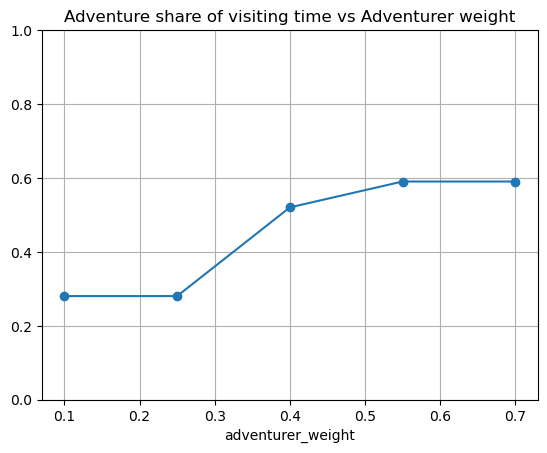

In [38]:
load_city(REQ["city"], REQ.get("country", ""))   # the batch run may have switched cities
sweep = []
for wa in [0.1, 0.25, 0.4, 0.55, 0.7]:
    rest = (1 - wa) / 3
    w = {"adventurer": wa, "foodie": rest, "culture": rest, "budget": rest}
    s = select_places(POOL, PERSONA_OUT, w, REQ)
    pl = optimise_route(s["selected"], REQ, score=s["score"])   # optimiser only, no LLM calls
    m = plan_metrics(pl, REQ, w)
    sweep.append({"adventurer_weight": wa, "adventure_time_share": m["persona_share"]["adventurer"],
                  "alignment": m["persona_alignment"]})
SWEEP = pd.DataFrame(sweep)
display(SWEEP)
SWEEP.plot(x="adventurer_weight", y="adventure_time_share", marker="o", legend=False,
           title="Adventure share of visiting time vs Adventurer weight", ylim=(0, 1), grid=True);

### Temperature experiment (Topic 5) **[B]**
Run the persona agents twice at each temperature on the same request and pool. **Diversity** = 1 − Jaccard
overlap between the two runs' selected places (higher = more varied). Also track how many violations the
pre-repair plan has. Cost: 4 personas × 2 runs × 3 temperatures = 24 small-model calls.

In [40]:
RUN_TEMP_EXPERIMENT = True
if RUN_TEMP_EXPERIMENT:
    load_city(REQ["city"], REQ.get("country", ""))
    trows = []
    for temp in [0.2, 0.7, 1.0]:
        sels = []
        for run_id in (1, 2):
            pouts = run_personas(REQ, POOL, temp, run_id, verbose=False)
            s = select_places(POOL, pouts, WEIGHTS, REQ)
            pl = optimise_route(s["selected"], REQ, score=s["score"])
            sels.append(set(s["selected"]))
            trows.append({"temperature": temp, "run": run_id, "violations_before_repair": len(validate_plan(pl, REQ)),
                          "alignment": plan_metrics(pl, REQ, WEIGHTS)["persona_alignment"]})
        jac = len(sels[0] & sels[1]) / len(sels[0] | sels[1])
        trows.append({"temperature": temp, "run": "diversity", "violations_before_repair": None,
                      "alignment": None, "diversity": round(1 - jac, 3)})
    display(pd.DataFrame(trows))

Active city: Hanoi — 131 places (cached file; local price factor 0.5)
  routing: session element budget reached; estimating 6 pairs instead
  routing: session element budget reached; estimating 4 pairs instead
  routing: session element budget reached; estimating 2 pairs instead
  routing: session element budget reached; estimating 2 pairs instead
  routing: session element budget reached; estimating 4 pairs instead
  routing: session element budget reached; estimating 10 pairs instead
    ⏳ pacing openai/gpt-oss-20b: waiting 57s for the per-minute token limit
    ⏳ pacing openai/gpt-oss-20b: waiting 1s for the per-minute token limit
  routing: session element budget reached; estimating 2 pairs instead
  routing: session element budget reached; estimating 2 pairs instead
    ⏳ pacing openai/gpt-oss-20b: waiting 57s for the per-minute token limit
    ⏳ pacing openai/gpt-oss-20b: waiting 57s for the per-minute token limit
  routing: session element budget reached; estimating 26 pairs ins

,temperature,run,violations_before_repair,alignment,diversity
0,0.2,1,0.0,0.641,NaN
1,0.2,2,0.0,0.833,NaN
2,0.2,diversity,NaN,NaN,0.444
3,0.7,1,1.0,0.726,NaN
4,0.7,2,0.0,0.741,NaN
5,0.7,diversity,NaN,NaN,0.308
6,1.0,1,2.0,0.642,NaN
7,1.0,2,1.0,0.630,NaN
8,1.0,diversity,NaN,NaN,0.357


### Judge the judge — agreement with human labels (Topic 6) **[A+B]**
Each of you reads ~10 cases (multi-agent vs baseline, shown blind) and records which one you would rather follow.
Then compare with the pairwise judge. Report the agreement, and how many verdicts were **inconsistent** across the
order swap (those are position bias, not judgements).

In [53]:
# Human labels from the blind read: "Your pick: A|B|tie" in eval/blind/plans.md, unblinded with key.json.
BLIND_DIR = os.path.join(BASE_DIR, "eval", "blind")
_key = json.load(open(os.path.join(BLIND_DIR, "key.json")))
HUMAN_LABELS = {}   # case id -> "multi_agent" | "baseline" | "tie"
for sec in open(os.path.join(BLIND_DIR, "plans.md"), encoding="utf-8").read().split("\n# "):
    tid, pick = re.match(r"#? ?(\S+):", sec), re.search(r"^Your pick:[ \t]*(A|B|tie)\b", sec, re.M | re.I)
    if tid and pick:
        p = pick.group(1).upper()
        HUMAN_LABELS[tid.group(1)] = "tie" if p == "TIE" else _key[tid.group(1)][p]
print(f"{len(HUMAN_LABELS)} human labels:", dict(Counter(HUMAN_LABELS.values())))
pairs = [(t, lab, RESULTS[t]["eval"]["judge"]["verdict"]) for t, lab in HUMAN_LABELS.items() if t in RESULTS]
if pairs:
    agree = sum(l == j for _, l, j in pairs) / len(pairs)
    print(f"Judge agrees with humans on {agree:.0%} of {len(pairs)} labelled cases")
    print("Inconsistent (flipped with order):", sum(j == "inconsistent" for _, _, j in pairs))
else:
    print("Add HUMAN_LABELS to compute agreement.")

12 human labels: {'multi_agent': 10, 'baseline': 2}
Judge agrees with humans on 42% of 12 labelled cases
Inconsistent (flipped with order): 3


### What it cost — LLM calls, tokens and seconds per agent

In [54]:
if CALL_LOG:
    cl = pd.DataFrame(CALL_LOG)
    display(cl.groupby(["agent", "model"]).agg(calls=("agent", "size"), prompt_tokens=("prompt_tokens", "sum"),
                                               completion_tokens=("completion_tokens", "sum"),
                                               seconds=("seconds", "sum")).round(1))
print(f"Google Routes elements used this session: {ROUTES_ELEMENTS_USED}")

,,calls,prompt_tokens,completion_tokens,seconds
agent,model,,,,
baseline,openai/gpt-oss-120b,4,6606,3469,9.6
evaluator,gemini-3.5-flash,2,2424,230,7.2
feasibility,openai/gpt-oss-120b,9,14720,4905,14.5
judge,gemini-3.5-flash,10,8174,553,47.4
parser,openai/gpt-oss-20b,11,3995,1904,8.4
persona:adventurer,openai/gpt-oss-20b,11,16489,3836,9.8
persona:budget,openai/gpt-oss-20b,10,14874,3396,9.1
persona:culture,openai/gpt-oss-20b,10,14774,3424,9.8
persona:foodie,openai/gpt-oss-20b,10,14874,3216,8.5


Google Routes elements used this session: 2502
